# Evaluation Metrics for Natural Language Processing Tasks

## Part 1: Text Classification — Sentiment Analysis

### 1.1 Introduction

Text classification is a fundamental Natural Language Processing (NLP) task that assigns predefined categories to textual inputs.

In this experiment, we evaluate a pretrained Transformer-based sentiment classification model on real movie reviews.

### Objective

The objective is to assess the performance of a pretrained DistilBERT model on the IMDb sentiment analysis dataset.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC

### Experimental Setup

**Task:** Binary Sentiment Classification

**Dataset:** IMDb Movie Reviews (test split)

**Model:** `distilbert-base-uncased-finetuned-sst-2-english`

**Framework:** Hugging Face Transformers

**Evaluation strategy:** Inference on a reproducible subset of unseen IMDb test reviews.

The model was fine-tuned for sentiment analysis using SST-2. Evaluating it on IMDb allows us to investigate its performance on a different sentiment dataset without additional training.

In [1]:

!pip -q install -U transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [2]:

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyTorch version: 2.14.1+cpu
Device: cpu


In [3]:

# Load the IMDb dataset using its full repository ID
dataset = load_dataset(
    "stanfordnlp/imdb",
    split="test"
)

print("Original test dataset size:", len(dataset))
print("Features:", dataset.features)

# Select 500 reproducible samples
test_dataset = dataset.shuffle(seed=SEED).select(
    range(500)
)

df = test_dataset.to_pandas()

df["sentiment"] = df["label"].map({
    0: "Negative",
    1: "Positive"
})

print("\nSelected samples:", len(df))

print("\nClass distribution:")
print(df["sentiment"].value_counts())

display(df.head())


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (2 outputs left out)

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Original test dataset size: 25000
Features: {'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

Selected samples: 500

Class distribution:
sentiment
Negative    254
Positive    246
Name: count, dtype: int64


,text,label,sentiment
0,<br /><br />When I unsuspectedly rented A Thou...,1,Positive
1,This is the latest entry in the long series of...,1,Positive
2,This movie was so frustrating. Everything seem...,0,Negative
3,"I was truly and wonderfully surprised at ""O' B...",1,Positive
4,This movie spends most of its time preaching t...,0,Negative


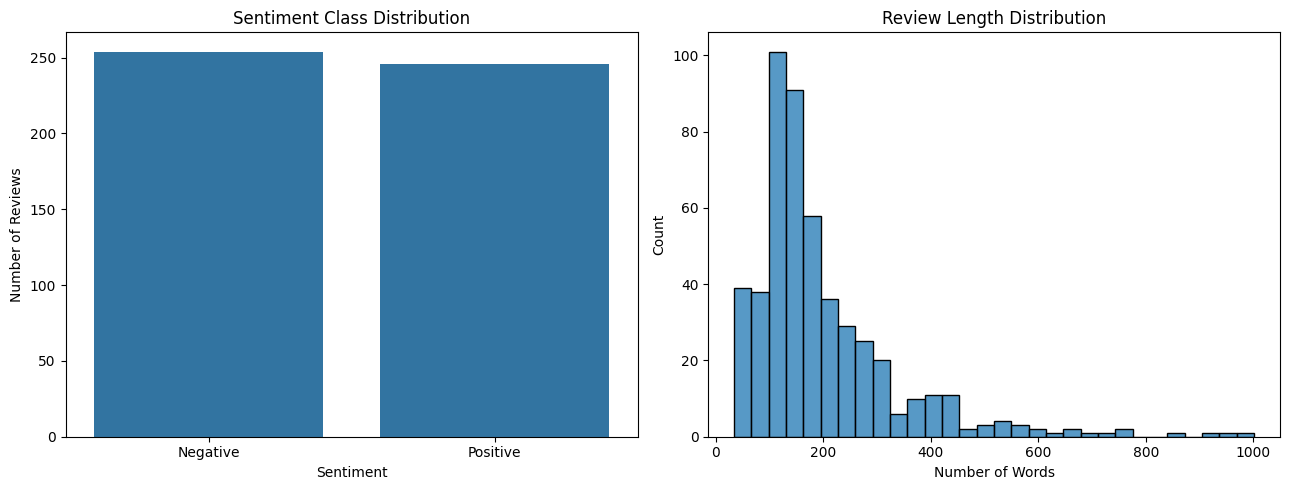


Review Length Statistics:


count     500.000000
mean      198.686000
std       140.306933
min        34.000000
25%       119.000000
50%       154.500000
75%       241.000000
max      1001.000000
Name: review_length, dtype: float64

In [4]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Class distribution
sns.countplot(
    data=df,
    x="sentiment",
    order=["Negative", "Positive"],
    ax=axes[0]
)

axes[0].set_title("Sentiment Class Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of Reviews")

# Review length distribution
df["review_length"] = df["text"].apply(
    lambda x: len(x.split())
)

sns.histplot(
    data=df,
    x="review_length",
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Review Length Distribution")
axes[1].set_xlabel("Number of Words")

plt.tight_layout()
plt.show()

print("\nReview Length Statistics:")
display(df["review_length"].describe())


### Dataset Exploration and Analysis

The IMDb dataset contains 25,000 reviews in its test split. For this experiment, a reproducible subset of 500 reviews was selected using a fixed random seed of 42.

#### Sentiment Class Distribution

The selected dataset contains:

- **254 negative reviews (50.8%)**
- **246 positive reviews (49.2%)**

The class distribution is nearly balanced, with only eight more negative reviews than positive reviews.

This balance is beneficial for evaluation because both sentiment categories are represented in similar proportions. Consequently, accuracy provides a meaningful overview of performance, although Precision, Recall, and F1-score remain necessary for a more detailed analysis.

#### Review Length Distribution

The review-length analysis produced the following statistics:

| Statistic | Number of Words |
|---|---:|
| Minimum | 34 |
| Mean | 198.69 |
| Median | 154.50 |
| Maximum | 1001 |
| Standard deviation | 140.31 |

The histogram shows that most reviews are relatively short or medium-length, while a smaller number contain substantially more words.

The distribution is positively skewed, with a long tail extending toward reviews containing approximately 1,000 words.

This variation in review length is relevant because DistilBERT processes a maximum of 512 tokens in this experiment. Longer reviews may therefore be truncated, potentially removing information useful for sentiment classification.

**Observation:** The dataset is suitable for evaluating binary sentiment classification, but review-length variation and possible truncation should be considered when interpreting model performance.

In [5]:

MODEL_NAME = (
    "distilbert-base-uncased-finetuned-sst-2-english"
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
)

model.to(device)
model.eval()

print("Model loaded successfully!")
print("Model:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)
print("Label mapping:", model.config.id2label)


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully!
Model: distilbert-base-uncased-finetuned-sst-2-english
Number of labels: 2
Label mapping: {0: 'NEGATIVE', 1: 'POSITIVE'}


In [6]:

# Tokenize reviews
encoded_dataset = tokenizer(
    df["text"].tolist(),
    truncation=True,
    padding=True,
    max_length=512,
    return_tensors="pt"
)

print("Input IDs shape:", encoded_dataset["input_ids"].shape)
print("Attention mask shape:", encoded_dataset["attention_mask"].shape)


Input IDs shape: torch.Size([500, 512])
Attention mask shape: torch.Size([500, 512])


In [7]:

batch_size = 16

predictions = []
probabilities = []

model.eval()

with torch.inference_mode():

    for start in tqdm(
        range(0, len(df), batch_size),
        desc="Running DistilBERT inference"
    ):

        end = start + batch_size

        batch = {
            key: value[start:end].to(device)
            for key, value in encoded_dataset.items()
        }

        outputs = model(**batch)

        probs = torch.softmax(
            outputs.logits,
            dim=-1
        )

        preds = torch.argmax(
            probs,
            dim=-1
        )

        predictions.extend(
            preds.cpu().numpy().tolist()
        )

        probabilities.extend(
            probs[:, 1].cpu().numpy().tolist()
        )

df["predicted_label"] = predictions
df["positive_probability"] = probabilities

df["predicted_sentiment"] = df["predicted_label"].map({
    0: "Negative",
    1: "Positive"
})

df["correct"] = (
    df["label"] == df["predicted_label"]
)

display(
    df[[
        "text",
        "sentiment",
        "predicted_sentiment",
        "positive_probability",
        "correct"
    ]].head(10)
)

print("Total predictions:", len(predictions))


Running DistilBERT inference:   0%|          | 0/32 [00:00<?, ?it/s]

,text,sentiment,predicted_sentiment,positive_probability,correct
0,<br /><br />When I unsuspectedly rented A Thou...,Positive,Positive,0.998876,True
1,This is the latest entry in the long series of...,Positive,Positive,0.996983,True
2,This movie was so frustrating. Everything seem...,Negative,Negative,0.002756,True
3,"I was truly and wonderfully surprised at ""O' B...",Positive,Negative,0.350793,False
4,This movie spends most of its time preaching t...,Negative,Negative,0.001497,True
5,After a very long time Marathi cinema has come...,Positive,Positive,0.999742,True
6,"This is a really sad, and touching movie! It d...",Positive,Positive,0.996830,True
7,Don't pay any attention to the rave reviews of...,Negative,Negative,0.000417,True
8,Porn legend Gregory Dark directs this cheesy h...,Negative,Negative,0.001930,True
9,This was a great movie. Something not only for...,Positive,Positive,0.999727,True


Total predictions: 500


### Analysis of DistilBERT Predictions

The pretrained DistilBERT model was used to generate sentiment predictions for 500 IMDb movie reviews.

The model assigns each review to one of two categories:

- **Negative (0)**
- **Positive (1)**

For each review, the model also produces a probability score representing its estimated confidence in the positive sentiment class.

#### Initial Observations

The displayed prediction examples show that the model correctly classifies most of the first ten reviews.

For instance, the first positive review receives a positive probability of approximately 0.9989, indicating a high-confidence positive prediction.

Similarly, the third review is correctly classified as negative, with a positive probability of approximately 0.0028.

However, the fourth review is incorrectly classified as negative despite having a positive reference label. Its predicted positive probability is approximately 0.3508.

This example demonstrates that model predictions are not always correct, even when the model assigns a relatively confident score to a class.

It is also important to distinguish predicted probabilities from guaranteed correctness: neural network confidence scores are not necessarily perfectly calibrated.

#### Inference Process

The model generated predictions in 32 batches using a batch size of 16.

Inference was performed without additional training or fine-tuning.

The model had previously been fine-tuned on the SST-2 sentiment dataset and was evaluated here on IMDb reviews, allowing us to examine its generalization to a different sentiment analysis dataset.

In [8]:

y_true = df["label"].to_numpy()
y_pred = df["predicted_label"].to_numpy()
y_prob = df["positive_probability"].to_numpy()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

print("=== DistilBERT Evaluation Results ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)


=== DistilBERT Evaluation Results ===
Accuracy:  0.8900
Precision: 0.9099
Recall:    0.8618
F1-score:  0.8852
ROC-AUC:   0.9537

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.92      0.89       254
    Positive       0.91      0.86      0.89       246

    accuracy                           0.89       500
   macro avg       0.89      0.89      0.89       500
weighted avg       0.89      0.89      0.89       500



### 1.4 Evaluation Results and Interpretation

The DistilBERT sentiment classification model was evaluated on 500 IMDb movie reviews.

The following results were obtained:

| Evaluation Metric | Score |
|---|---:|
| Accuracy | 0.8900 |
| Precision (Positive Class) | 0.9099 |
| Recall (Positive Class) | 0.8618 |
| F1-score (Positive Class) | 0.8852 |
| ROC-AUC | 0.9537 |

#### 1. Accuracy

The model achieves an accuracy of **89.00%**, correctly classifying 445 out of 500 movie reviews.

This indicates that the model performs well on the selected IMDb test subset, despite having been fine-tuned on a different sentiment dataset.

#### 2. Precision

The model achieves a positive-class Precision of **90.99%**.

This means that approximately 91% of reviews predicted as positive are actually positive.

The result indicates that the model makes relatively few false positive predictions.

#### 3. Recall

The positive-class Recall is **86.18%**.

This means that the model correctly identifies approximately 86% of all genuinely positive reviews.

The remaining positive reviews are incorrectly classified as negative.

#### 4. F1-score

The positive-class F1-score is **88.52%**.

This metric combines Precision and Recall into a single measure.

The result indicates a strong balance between the reliability of positive predictions and the ability to identify positive reviews.

However, the higher Precision compared with Recall suggests that the model is more likely to miss some positive reviews than to incorrectly classify negative reviews as positive.

#### 5. ROC-AUC

The model achieves a ROC-AUC score of **0.9537**.

This indicates strong discrimination between positive and negative reviews across different classification thresholds.

The model generally assigns higher positive-class scores to genuinely positive reviews than to negative reviews.

#### 6. Class-Specific Performance

The classification report shows the following rounded results:

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Negative | 0.87 | 0.92 | 0.89 | 254 |
| Positive | 0.91 | 0.86 | 0.89 | 246 |

The negative class achieves higher Recall than the positive class.

This suggests that the model is more effective at detecting negative reviews, while some positive reviews are mistakenly classified as negative.

#### Overall Interpretation

The pretrained DistilBERT model demonstrates strong sentiment classification performance on the selected IMDb reviews.

Its high Accuracy, F1-score, and ROC-AUC indicate that it can generalize reasonably well to a sentiment dataset different from the one used during fine-tuning.

Nevertheless, the results are based on a subset of 500 reviews and should not be interpreted as performance estimates for the entire IMDb test set without further evaluation.

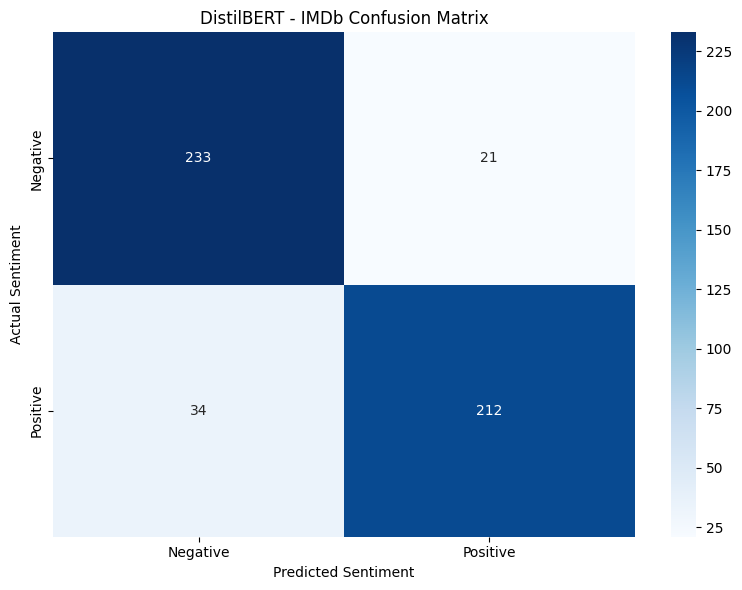

True Negatives: 233
False Positives: 21
False Negatives: 34
True Positives: 212


In [9]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("DistilBERT - IMDb Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


### Confusion Matrix Analysis

The confusion matrix provides a detailed representation of the classification performance of DistilBERT on the IMDb test subset.

The following results were obtained:

| Prediction Outcome | Number of Reviews |
|---|---:|
| True Negatives (TN) | 233 |
| False Positives (FP) | 21 |
| False Negatives (FN) | 34 |
| True Positives (TP) | 212 |

#### Interpretation

**True Negatives (233):** The model correctly classified 233 negative movie reviews.

**True Positives (212):** The model correctly identified 212 positive movie reviews.

**False Positives (21):** The model incorrectly classified 21 negative reviews as positive.

**False Negatives (34):** The model incorrectly classified 34 positive reviews as negative.

Overall, the model correctly classified 445 out of 500 reviews, achieving an accuracy of 89%.

#### Error Distribution

The model produces more false negatives (34) than false positives (21).

This suggests that the classifier is more likely to incorrectly reject a positive review than to incorrectly identify a negative review as positive.

The Recall for negative reviews is approximately 91.73%, compared with 86.18% for positive reviews.

This difference indicates that the model is slightly more effective at recognizing negative sentiment.

#### Conclusion

The confusion matrix confirms that DistilBERT achieves strong overall classification performance, while revealing a moderate tendency to misclassify positive reviews as negative.

This analysis complements the aggregate evaluation metrics by identifying the types and distribution of classification errors.

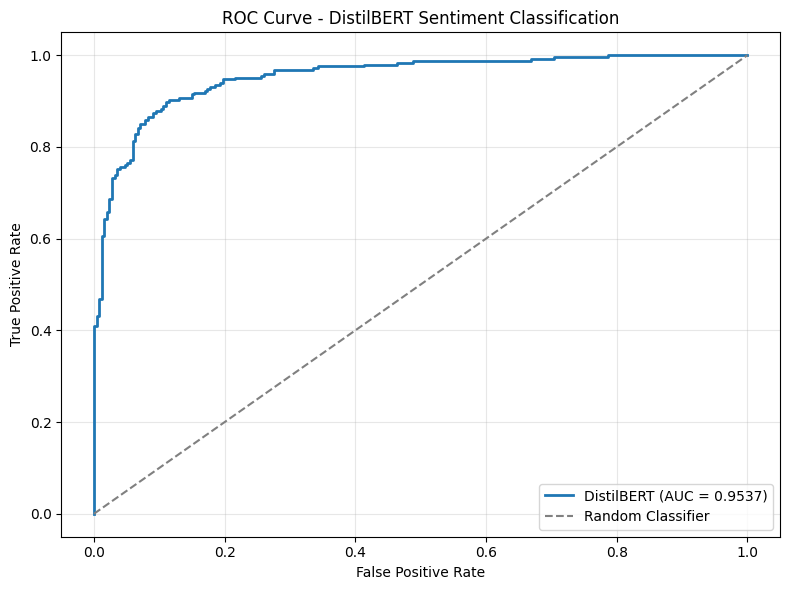

In [10]:

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"DistilBERT (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - DistilBERT Sentiment Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### ROC Curve and AUC Analysis

The Receiver Operating Characteristic (ROC) curve evaluates the ability of the classification model to distinguish between positive and negative sentiment across different decision thresholds.

The curve represents the relationship between:

- **True Positive Rate (TPR):** The proportion of positive reviews correctly identified.
- **False Positive Rate (FPR):** The proportion of negative reviews incorrectly classified as positive.

The diagonal dashed line represents the expected performance of a random classifier.

#### Experimental Result

The DistilBERT model achieved:

**ROC-AUC = 0.9537**

The ROC curve is positioned substantially above the random-classifier baseline and approaches the upper-left corner of the graph.

This indicates that the model can achieve high True Positive Rates while maintaining relatively low False Positive Rates across a range of classification thresholds.

#### Interpretation

An AUC of 0.9537 indicates excellent discrimination between the two sentiment classes.

In probabilistic terms, the model has approximately a 95.37% chance of assigning a higher positive-class score to a randomly selected positive review than to a randomly selected negative review, with ties handled appropriately.

This result complements the accuracy and F1-score because ROC-AUC evaluates the ranking quality of predicted scores across thresholds rather than performance at a single classification threshold.

#### Conclusion

The ROC analysis confirms that DistilBERT has strong discriminative ability on the selected IMDb test reviews.

However, ROC-AUC does not directly measure probability calibration, and strong discrimination does not guarantee that every individual prediction is correct.

Total misclassified reviews: 55

Errors by actual sentiment:
sentiment
Positive    34
Negative    21
Name: count, dtype: int64

Average review length:
correct
False    210.927273
True     197.173034
Name: review_length, dtype: float64


,text,sentiment,predicted_sentiment,positive_probability,review_length
3,"I was truly and wonderfully surprised at ""O' B...",Positive,Negative,0.350793,111
17,"A holiday on a boat, a married couple, an angr...",Negative,Positive,0.686230,284
34,"""An astronaut (Michael Emmet) dies while retur...",Negative,Positive,0.575033,150
55,I remember seeing this film in the mid 80's th...,Positive,Negative,0.002091,130
59,"Sex, drugs, racism and of course you ABC's. Wh...",Positive,Negative,0.000525,161
68,"When I was young, I was a big fan of the Naked...",Positive,Negative,0.268933,143
79,"First, the positives: an excellent job at depi...",Positive,Negative,0.065380,86
88,i was having a horrid day but this movie grabb...,Positive,Negative,0.219834,744
90,"Just watched this today on TCM, where the othe...",Negative,Positive,0.742332,281
98,There are few films that deal with things that...,Positive,Negative,0.012342,287


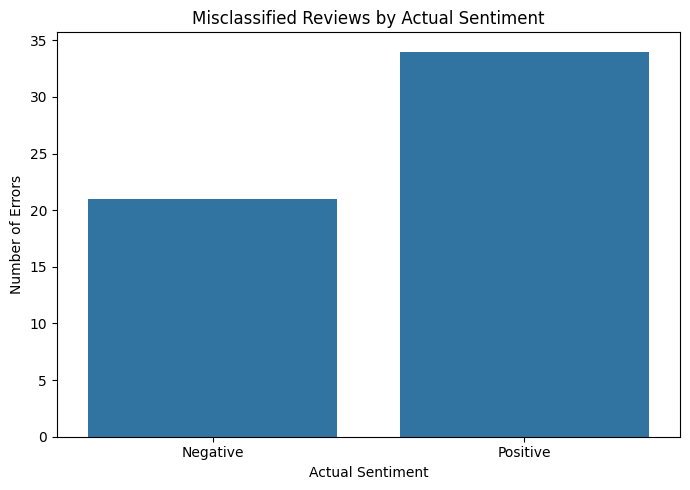

In [11]:

# Extract incorrectly classified reviews
errors_df = df[df["correct"] == False].copy()

print("Total misclassified reviews:", len(errors_df))

print("\nErrors by actual sentiment:")
print(errors_df["sentiment"].value_counts())

# Compare review lengths
print("\nAverage review length:")
print(
    df.groupby("correct")["review_length"].mean()
)

# Display misclassified examples
display(
    errors_df[[
        "text",
        "sentiment",
        "predicted_sentiment",
        "positive_probability",
        "review_length"
    ]].head(10)
)

# Visualize errors by actual class
plt.figure(figsize=(7, 5))

sns.countplot(
    data=errors_df,
    x="sentiment",
    order=["Negative", "Positive"]
)

plt.title("Misclassified Reviews by Actual Sentiment")
plt.xlabel("Actual Sentiment")
plt.ylabel("Number of Errors")

plt.tight_layout()
plt.show()


### Error Analysis

Error analysis is essential for understanding the limitations of a classification model beyond aggregate evaluation metrics.

In this experiment, DistilBERT incorrectly classified **55 out of 500 reviews**, corresponding to an error rate of 11%.

#### 1. Distribution of Classification Errors

The errors are distributed as follows:

| Actual Sentiment | Misclassified Reviews | Error Rate Within Class |
|---|---:|---:|
| Negative | 21 | 8.27% |
| Positive | 34 | 13.82% |
| **Total** | **55** | **11.00% overall** |

The model makes more mistakes on positive reviews than on negative reviews.

Specifically, 34 positive reviews were classified as negative, compared with 21 negative reviews classified as positive.

This finding is consistent with the confusion matrix and the lower Recall observed for the positive class.

#### 2. Relationship Between Review Length and Errors

The average review lengths are:

| Prediction Outcome | Average Number of Words |
|---|---:|
| Correct Predictions | 197.17 |
| Incorrect Predictions | 210.93 |

Misclassified reviews are, on average, approximately 13.76 words longer than correctly classified reviews.

This observation suggests a possible relationship between review length and classification difficulty.

However, the difference is relatively small and does not establish that longer reviews cause classification errors.

Further analysis would be required to determine whether review length, token truncation, or other linguistic characteristics significantly influence model performance.

#### 3. Analysis of Individual Errors

The displayed examples show that DistilBERT sometimes produces incorrect predictions with high confidence.

For example, one positive review receives a positive probability of approximately 0.0021, indicating that the model strongly favors the negative class despite the positive reference label.

Other errors occur with probabilities closer to the decision boundary, such as a negative review incorrectly predicted as positive with a positive probability of approximately 0.5750.

These examples demonstrate that classification errors can occur both when the model is uncertain and when it is highly confident.

#### 4. Possible Sources of Errors

Several factors may contribute to incorrect sentiment predictions:

- **Complex language:** Reviews may contain mixed sentiments, nuanced opinions, or ambiguous expressions.
- **Sarcasm and irony:** The literal meaning of a sentence may differ from its intended sentiment.
- **Long reviews:** Important information may be truncated because the model processes a maximum of 512 tokens.
- **Domain differences:** The model was fine-tuned on SST-2 and evaluated on IMDb reviews, which may contain different writing styles and vocabulary.

These are possible explanations rather than experimentally confirmed causes of the observed errors.

#### Conclusion

The error analysis reveals that DistilBERT performs well overall but makes more errors when identifying positive sentiment.

The results also highlight the importance of examining individual predictions, review characteristics, and model confidence rather than relying exclusively on aggregate performance scores.

### Conclusion: Text Classification Evaluation

This experiment evaluated a pretrained DistilBERT sentiment classification model on a reproducible subset of 500 real IMDb movie reviews.

The model was evaluated without additional fine-tuning, using Accuracy, Precision, Recall, F1-score, ROC-AUC, a confusion matrix, and error analysis.

#### Summary of Experimental Results

| Metric | Result |
|---|---:|
| Accuracy | 89.00% |
| Precision (Positive Class) | 90.99% |
| Recall (Positive Class) | 86.18% |
| F1-score (Positive Class) | 88.52% |
| ROC-AUC | 0.9537 |
| Correct Predictions | 445 |
| Incorrect Predictions | 55 |

#### Main Findings

The pretrained DistilBERT model demonstrated strong binary sentiment classification performance on the selected IMDb reviews.

The accuracy of 89% indicates that most reviews were correctly classified.

The F1-score of 88.52% reflects a strong balance between Precision and Recall for the positive class.

The ROC-AUC score of 0.9537 demonstrates excellent discrimination between positive and negative reviews across different decision thresholds.

However, the confusion matrix revealed that the model produced more false negatives than false positives, indicating greater difficulty in identifying positive reviews.

The error analysis also showed that incorrectly classified reviews were slightly longer on average, although further investigation would be necessary to establish the significance of this difference.

#### Experimental Limitations

Several limitations should be considered:

1. The experiment used only 500 reviews from the IMDb test dataset.
2. The model was pretrained and fine-tuned on SST-2 rather than IMDb.
3. Reviews exceeding the model's maximum input length were truncated.
4. Only one sentiment classification model was evaluated.
5. No additional fine-tuning or hyperparameter optimization was performed.

#### Final Conclusion

The experiment demonstrates the importance of combining multiple evaluation metrics when assessing NLP classification systems.

Accuracy provides an overall measure of correctness, while Precision, Recall, and F1-score offer more detailed information about class-specific performance.

The confusion matrix identifies classification errors, and ROC-AUC evaluates the model's discriminative ability across thresholds.

Overall, DistilBERT achieved promising performance on the selected IMDb test subset, demonstrating the ability of pretrained Transformer models to generalize across sentiment analysis datasets.

The next experiment will investigate evaluation metrics for sequence labeling through Named Entity Recognition using a real pretrained model and a benchmark dataset.

## Part 2: Sequence Labeling — Named Entity Recognition

### 2.1 Introduction

Sequence labeling is a Natural Language Processing task that assigns a label to each token in a sequence.

Named Entity Recognition (NER) is a sequence labeling task that identifies and classifies named entities in text.

NER systems are widely used in information extraction, document processing, search engines, and question-answering applications.

### Named Entity Categories

The CoNLL-2003 dataset contains four entity categories:

- **PER:** Person
- **ORG:** Organization
- **LOC:** Location
- **MISC:** Miscellaneous named entities

### BIO Tagging Scheme

The BIO tagging scheme represents entity boundaries using:

- **B:** Beginning of an entity
- **I:** Inside an entity
- **O:** Outside any entity

For example:

Sentence: "Barack Obama visited New York."

| Token | NER Tag |
|---|---|
| Barack | B-PER |
| Obama | I-PER |
| visited | O |
| New | B-LOC |
| York | I-LOC |
| . | O |

### Experimental Objective

The objective of this experiment is to evaluate a pretrained BERT-based Named Entity Recognition model using real annotated data.

The experiment will include:

1. Loading the CoNLL-2003 dataset.
2. Exploring entity labels and sentence structure.
3. Loading a pretrained BERT NER model.
4. Generating predictions on real sentences.
5. Aligning model predictions with reference labels.
6. Calculating token-level evaluation metrics.
7. Calculating entity-level Precision, Recall, and F1-score.
8. Visualizing and analyzing model errors.

### Experimental Setup

**Dataset:** CoNLL-2003 English NER

**Model:** `dslim/bert-base-NER`

**Evaluation:** 500 sentences from the test split

**Framework:** Hugging Face Transformers and seqeval

The model will be evaluated without additional training or fine-tuning.

In [12]:

!pip -q install -U transformers datasets accelerate seqeval scikit-learn pandas numpy matplotlib seaborn

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForTokenClassification
from seqeval.metrics import (
    precision_score as entity_precision,
    recall_score as entity_recall,
    f1_score as entity_f1,
    classification_report as entity_report
)
from seqeval.scheme import IOB2

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("NER evaluation environment ready!")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Device: cpu
NER evaluation environment ready!


In [13]:

from datasets import load_dataset

# Load CoNLL-2003 from a compatible repository
ner_dataset = load_dataset("lhoestq/conll2003")

print("Dataset:")
print(ner_dataset)

print("\nDataset features:")
print(ner_dataset["test"].features)

# Select 500 reproducible test sentences
ner_test = (
    ner_dataset["test"]
    .shuffle(seed=SEED)
    .select(range(500))
)

print("\nSelected test sentences:", len(ner_test))

# Retrieve NER label names
ner_feature = ner_dataset["test"].features["ner_tags"]

if hasattr(ner_feature.feature, "names"):
    label_names = ner_feature.feature.names
else:
    label_names = [
        "O",
        "B-PER", "I-PER",
        "B-ORG", "I-ORG",
        "B-LOC", "I-LOC",
        "B-MISC", "I-MISC"
    ]

print("\nNER Labels:")
print(label_names)

print("\nExample sentence:")
print(ner_test[0]["tokens"])

print("\nReference NER tags:")
print([
    label_names[i]
    for i in ner_test[0]["ner_tags"]
])


dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

Dataset:
DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})

Dataset features:
{'id': Value('string'), 'tokens': List(Value('string')), 'pos_tags': List(Value('int64')), 'chunk_tags': List(Value('int64')), 'ner_tags': List(Value('int64'))}

Selected test sentences: 500

NER Labels:
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

Example sentence:
['Hartford', '4', 'BOSTON', '2']

Reference NER tags:
['B-ORG', 'O', 'B-ORG', 'O']


### Dataset Description

The experiment uses the CoNLL-2003 English Named Entity Recognition dataset, a widely used benchmark for sequence labeling.

The dataset contains:

| Split | Number of Sentences |
|---|---:|
| Training | 14,041 |
| Validation | 3,250 |
| Test | 3,453 |

For this experiment, 500 sentences were randomly selected from the test split using a fixed random seed of 42.

The dataset includes tokenized sentences and their corresponding annotations.

### Entity Categories

The dataset contains four named entity categories:

- **PER:** Person
- **ORG:** Organization
- **LOC:** Location
- **MISC:** Miscellaneous named entities

Annotations follow the BIO tagging scheme, which identifies the beginning and continuation of named entities.

### Example

The first selected sentence contains the following annotations:

| Token | Reference Tag |
|---|---|
| Hartford | B-ORG |
| 4 | O |
| BOSTON | B-ORG |
| 2 | O |

This example demonstrates how named entities are represented at the token level.

The use of a real annotated benchmark allows the pretrained BERT model to be evaluated against reference labels rather than manually simulated predictions.

,NER Tag,Count
1,O,5537
2,B-PER,257
0,B-ORG,252
4,B-LOC,231
3,I-PER,184
6,I-ORG,113
5,B-MISC,98
8,I-LOC,47
7,I-MISC,40


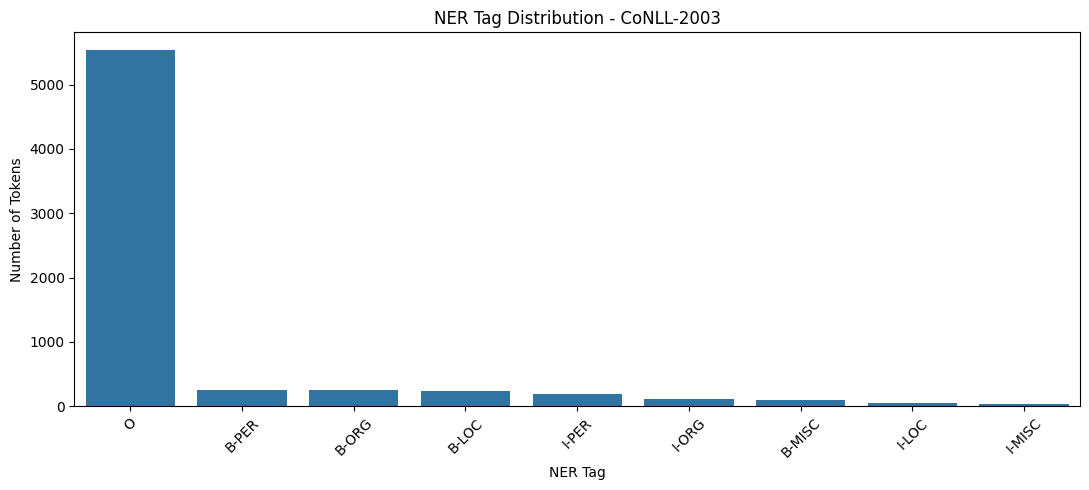


Sentence Length Statistics:


count    500.00000
mean      13.51800
std       11.79508
min        1.00000
25%        5.00000
50%        9.00000
75%       20.25000
max       72.00000
dtype: float64

In [14]:

from collections import Counter

# Count NER tags
all_ner_tags = []

for example in ner_test:
    all_ner_tags.extend(
        [
            label_names[tag_id]
            for tag_id in example["ner_tags"]
        ]
    )

tag_counts = Counter(all_ner_tags)

tag_df = pd.DataFrame(
    tag_counts.items(),
    columns=["NER Tag", "Count"]
).sort_values("Count", ascending=False)

display(tag_df)

# Plot tag distribution
plt.figure(figsize=(11, 5))

sns.barplot(
    data=tag_df,
    x="NER Tag",
    y="Count"
)

plt.title("NER Tag Distribution - CoNLL-2003")
plt.xticks(rotation=45)
plt.ylabel("Number of Tokens")
plt.tight_layout()
plt.show()

# Sentence length statistics
sentence_lengths = [
    len(example["tokens"])
    for example in ner_test
]

print("\nSentence Length Statistics:")
display(pd.Series(sentence_lengths).describe())


### Dataset Exploration and Analysis

The selected CoNLL-2003 test subset contains 500 sentences.

#### NER Tag Distribution

The distribution of BIO tags is as follows:

| NER Tag | Number of Tokens |
|---|---:|
| O | 5,537 |
| B-PER | 257 |
| B-ORG | 252 |
| B-LOC | 231 |
| I-PER | 184 |
| I-ORG | 113 |
| B-MISC | 98 |
| I-LOC | 47 |
| I-MISC | 40 |

The dataset contains 6,759 tokens in total.

The non-entity label "O" represents approximately 81.92% of all tokens.

This indicates a substantial imbalance between non-entity tokens and entity-related labels.

Consequently, a model that correctly predicts most "O" labels may achieve high token-level accuracy even if it makes mistakes when identifying named entities.

This motivates the use of entity-level Precision, Recall, and F1-score.

#### Sentence Length Distribution

The sentence-length statistics are:

| Statistic | Number of Tokens |
|---|---:|
| Minimum | 1 |
| Mean | 13.52 |
| Median | 9 |
| Maximum | 72 |
| Standard deviation | 11.80 |

The selected sentences are relatively short, with an average length of approximately 14 tokens.

The median sentence length is 9 tokens, indicating that half of the sentences contain no more than 9 tokens.

Some sentences are considerably longer, reaching up to 72 tokens.

#### Observation

The dataset contains a large proportion of non-entity tokens and relatively short sentences.

These characteristics should be considered when interpreting token-level evaluation metrics, particularly accuracy.

Entity-level metrics are necessary to determine whether the model correctly identifies complete named entities and their categories.

In [15]:

NER_MODEL_NAME = "dslim/bert-base-NER"

ner_tokenizer = AutoTokenizer.from_pretrained(
    NER_MODEL_NAME,
    use_fast=True
)

ner_model = AutoModelForTokenClassification.from_pretrained(
    NER_MODEL_NAME
)

ner_model.to(device)
ner_model.eval()

print("Model loaded successfully!")
print("Model:", NER_MODEL_NAME)

print("\nModel labels:")
print(ner_model.config.id2label)


config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded successfully!
Model: dslim/bert-base-NER

Model labels:
{0: 'O', 1: 'B-MISC', 2: 'I-MISC', 3: 'B-PER', 4: 'I-PER', 5: 'B-ORG', 6: 'I-ORG', 7: 'B-LOC', 8: 'I-LOC'}


In [16]:

ner_true = []
ner_pred = []
ner_tokens = []

for example in tqdm(
    ner_test,
    desc="Running BERT NER inference"
):

    words = example["tokens"]

    true_tags = [
        label_names[i]
        for i in example["ner_tags"]
    ]

    encoding = ner_tokenizer(
        words,
        is_split_into_words=True,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    word_ids = encoding.word_ids(batch_index=0)

    inputs = {
        key: value.to(device)
        for key, value in encoding.items()
    }

    with torch.inference_mode():
        outputs = ner_model(**inputs)

    predicted_ids = torch.argmax(
        outputs.logits,
        dim=-1
    )[0].cpu().tolist()

    # Keep first subword prediction for each word
    predicted_word_tags = []
    previous_word_id = None

    for token_index, word_id in enumerate(word_ids):

        if word_id is None:
            continue

        if word_id != previous_word_id:

            predicted_tag = ner_model.config.id2label[
                predicted_ids[token_index]
            ]

            predicted_word_tags.append(
                predicted_tag
            )

        previous_word_id = word_id

    # Ensure alignment for non-truncated sentences
    if len(predicted_word_tags) != len(words):
        raise ValueError(
            "A sentence was truncated during tokenization. "
            "Adjust the evaluation strategy."
        )

    ner_true.append(true_tags)
    ner_pred.append(predicted_word_tags)
    ner_tokens.append(words)

print("Total evaluated sentences:", len(ner_true))

print("\nExample predictions:")

example_df = pd.DataFrame({
    "Token": ner_tokens[0],
    "True Tag": ner_true[0],
    "Predicted Tag": ner_pred[0]
})

display(example_df)


Running BERT NER inference:   0%|          | 0/500 [00:00<?, ?it/s]

Total evaluated sentences: 500

Example predictions:


,Token,True Tag,Predicted Tag
0,Hartford,B-ORG,B-ORG
1,4,O,O
2,BOSTON,B-ORG,B-ORG
3,2,O,O


### Analysis of BERT NER Predictions

The pretrained `dslim/bert-base-NER` model was used to generate Named Entity Recognition predictions for 500 sentences from the CoNLL-2003 test dataset.

The model assigns BIO tags to individual words, allowing named entities to be identified and classified.

### Subword Tokenization

BERT uses WordPiece tokenization, which may divide words into smaller subword units.

To compare model predictions with the dataset annotations, predictions were aligned with the original words by selecting the label predicted for the first subword of each word.

This alignment step is essential because the reference annotations are defined at the word level rather than the subword level.

### Example Prediction

The first evaluated sentence produced the following results:

| Token | Reference Tag | Predicted Tag |
|---|---|---|
| Hartford | B-ORG | B-ORG |
| 4 | O | O |
| BOSTON | B-ORG | B-ORG |
| 2 | O | O |

All four tokens in this example were correctly classified.

The model successfully identified "Hartford" and "BOSTON" as organizations according to the reference annotations.

### Observation

The model generated predictions for all 500 selected sentences without requiring additional training.

The successful alignment between predicted labels and reference annotations enables the calculation of both token-level and entity-level evaluation metrics.

However, correct predictions on one example do not establish overall model performance. A comprehensive evaluation requires analyzing predictions across the entire test subset.

In [17]:

# Flatten token labels
true_flat = [
    tag
    for sentence in ner_true
    for tag in sentence
]

pred_flat = [
    tag
    for sentence in ner_pred
    for tag in sentence
]

token_accuracy = accuracy_score(
    true_flat,
    pred_flat
)

# Exclude O from macro-averaged entity-tag metrics
entity_tags = [
    tag for tag in label_names
    if tag != "O"
]

token_precision = precision_score(
    true_flat,
    pred_flat,
    labels=entity_tags,
    average="macro",
    zero_division=0
)

token_recall = recall_score(
    true_flat,
    pred_flat,
    labels=entity_tags,
    average="macro",
    zero_division=0
)

token_f1 = f1_score(
    true_flat,
    pred_flat,
    labels=entity_tags,
    average="macro",
    zero_division=0
)

print("=== Token-Level Evaluation ===")
print(f"Accuracy:  {token_accuracy:.4f}")
print(f"Precision: {token_precision:.4f}")
print(f"Recall:    {token_recall:.4f}")
print(f"F1-score:  {token_f1:.4f}")

print("\nToken-Level Classification Report:")
print(
    classification_report(
        true_flat,
        pred_flat,
        labels=entity_tags,
        zero_division=0
    )
)


=== Token-Level Evaluation ===
Accuracy:  0.9791
Precision: 0.8641
Recall:    0.9049
F1-score:  0.8830

Token-Level Classification Report:
              precision    recall  f1-score   support

       B-PER       0.97      0.96      0.97       257
       I-PER       0.98      0.99      0.99       184
       B-ORG       0.89      0.92      0.91       252
       I-ORG       0.90      0.88      0.89       113
       B-LOC       0.92      0.94      0.93       231
       I-LOC       0.88      0.96      0.92        47
      B-MISC       0.78      0.86      0.82        98
      I-MISC       0.58      0.72      0.64        40

   micro avg       0.91      0.93      0.92      1222
   macro avg       0.86      0.90      0.88      1222
weighted avg       0.91      0.93      0.92      1222



### Token-Level Evaluation Results

The BERT NER model was evaluated using token-level Accuracy, Precision, Recall, and F1-score.

The following results were obtained:

| Metric | Score |
|---|---:|
| Token Accuracy | 0.9791 |
| Macro Precision | 0.8641 |
| Macro Recall | 0.9049 |
| Macro F1-score | 0.8830 |

The macro-averaged Precision, Recall, and F1-score were calculated across the eight entity-related BIO tags, excluding the non-entity label "O".

#### 1. Token-Level Accuracy

The model achieved an accuracy of **97.91%**.

This indicates that approximately 98% of the tokens were assigned their correct BIO labels.

However, the dataset contains a high proportion of non-entity tokens, which can contribute substantially to overall accuracy.

Therefore, token-level accuracy alone is insufficient for evaluating complete entity recognition.

#### 2. Macro Precision

The macro Precision is **86.41%**.

This metric measures the reliability of the model's predictions across the entity-related BIO tags, giving equal importance to each tag.

#### 3. Macro Recall

The macro Recall is **90.49%**.

The result indicates that the model successfully identifies a large proportion of reference entity tags.

The higher Recall compared with Precision suggests that the model tends to identify entity tags more frequently than it predicts them with perfect precision.

#### 4. Macro F1-score

The macro F1-score is **88.30%**.

This result summarizes the balance between Precision and Recall across the entity-related BIO tags.

#### 5. Class-Specific Performance

The classification report reveals differences between BIO tags.

The highest F1-score is observed for **I-PER (0.99)**, followed by **B-PER (0.97)**.

The lowest F1-score is observed for **I-MISC (0.64)**.

This suggests that the model is particularly effective at recognizing person-related tags but encounters greater difficulty with miscellaneous entity tags.

#### Conclusion

The token-level evaluation demonstrates strong tagging performance.

However, because individual BIO tags do not fully represent complete named entities, entity-level evaluation is required to assess the model's ability to extract entities with correct boundaries and categories.

In [18]:

ner_precision = entity_precision(
    ner_true,
    ner_pred,
    mode="strict",
    scheme=IOB2
)

ner_recall = entity_recall(
    ner_true,
    ner_pred,
    mode="strict",
    scheme=IOB2
)

ner_f1 = entity_f1(
    ner_true,
    ner_pred,
    mode="strict",
    scheme=IOB2
)

print("=== Entity-Level Evaluation ===")

print(f"Precision: {ner_precision:.4f}")
print(f"Recall:    {ner_recall:.4f}")
print(f"F1-score:  {ner_f1:.4f}")

print("\nEntity-Level Classification Report:")

print(
    entity_report(
        ner_true,
        ner_pred,
        mode="strict",
        scheme=IOB2,
        digits=4,
        zero_division=0
    )
)


=== Entity-Level Evaluation ===
Precision: 0.9010
Recall:    0.9236
F1-score:  0.9122

Entity-Level Classification Report:
              precision    recall  f1-score   support

         LOC     0.9237    0.9437    0.9336       231
        MISC     0.7500    0.8265    0.7864        98
         ORG     0.8769    0.9048    0.8906       252
         PER     0.9686    0.9611    0.9648       257

   micro avg     0.9010    0.9236    0.9122       838
   macro avg     0.8798    0.9090    0.8939       838
weighted avg     0.9031    0.9236    0.9131       838



### Entity-Level Evaluation Results

Entity-level evaluation measures whether the model correctly identifies complete named entities, including their boundaries and categories.

The evaluation was performed using strict IOB2 matching through the seqeval library.

#### Overall Results

| Metric | Score |
|---|---:|
| Entity Precision | 0.9010 |
| Entity Recall | 0.9236 |
| Entity F1-score | 0.9122 |

#### 1. Entity Precision

The model achieved an entity-level Precision of **90.10%**.

This means that approximately 90% of the complete entities predicted by the model exactly match reference entities in both boundaries and categories.

#### 2. Entity Recall

The entity-level Recall is **92.36%**.

This indicates that the model correctly identifies approximately 92% of the reference named entities.

#### 3. Entity F1-score

The entity-level F1-score is **91.22%**.

This result demonstrates strong performance in extracting complete named entities.

Unlike token-level evaluation, strict entity-level evaluation considers an entity correct only when its complete span and category match the reference annotation.

#### 4. Performance by Entity Category

| Entity Type | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| LOC | 0.9237 | 0.9437 | 0.9336 | 231 |
| MISC | 0.7500 | 0.8265 | 0.7864 | 98 |
| ORG | 0.8769 | 0.9048 | 0.8906 | 252 |
| PER | 0.9686 | 0.9611 | 0.9648 | 257 |

The model performs best on **Person (PER)** entities, achieving an F1-score of 96.48%.

Location entities also achieve strong performance, with an F1-score of 93.36%.

Organization entities achieve an F1-score of 89.06%.

Miscellaneous entities obtain the lowest F1-score at 78.64%, indicating greater difficulty in recognizing this category.

#### 5. Token-Level vs Entity-Level Evaluation

The token-level macro F1-score is 88.30%, while the entity-level micro F1-score is 91.22%.

These scores use different averaging methods and evaluate different prediction units.

Therefore, the difference does not imply that entity-level evaluation is inherently easier than token-level evaluation.

Instead, the two metrics provide complementary information about the model's performance.

#### Conclusion

The entity-level evaluation confirms that the pretrained BERT model achieves strong Named Entity Recognition performance on the selected CoNLL-2003 test sentences.

The results demonstrate that the model is particularly effective at identifying person and location entities, while miscellaneous entities remain more challenging.

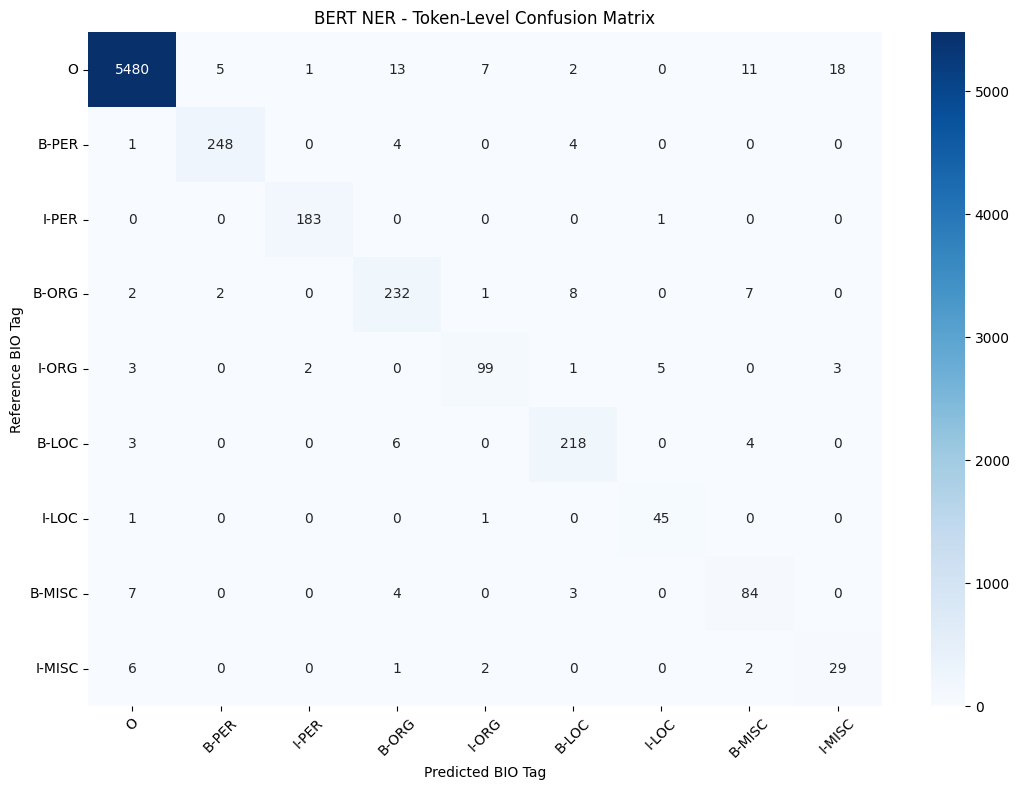

In [19]:

all_tags = label_names

cm_ner = confusion_matrix(
    true_flat,
    pred_flat,
    labels=all_tags
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm_ner,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=all_tags,
    yticklabels=all_tags
)

plt.title("BERT NER - Token-Level Confusion Matrix")
plt.xlabel("Predicted BIO Tag")
plt.ylabel("Reference BIO Tag")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### Token-Level Confusion Matrix Analysis

The confusion matrix provides a detailed representation of the BERT model's token-level classification performance on the CoNLL-2003 test subset.

Each row represents a reference BIO tag, while each column represents a predicted BIO tag.

The diagonal values correspond to correctly classified tokens, whereas off-diagonal values indicate prediction errors.

#### Main Observations

The model correctly classified:

- **5,480 tokens labeled O**
- **248 tokens labeled B-PER**
- **183 tokens labeled I-PER**
- **232 tokens labeled B-ORG**
- **99 tokens labeled I-ORG**
- **218 tokens labeled B-LOC**
- **45 tokens labeled I-LOC**
- **84 tokens labeled B-MISC**
- **29 tokens labeled I-MISC**

These results demonstrate that the majority of tokens are correctly assigned their reference BIO labels.

#### Classification Errors

The confusion matrix reveals several types of errors.

**1. Confusion between organizations and locations**

Eight B-ORG tokens were incorrectly predicted as B-LOC, while six B-LOC tokens were incorrectly predicted as B-ORG.

This indicates that the model occasionally confuses organizations with geographical locations.

**2. Confusion involving miscellaneous entities**

Seven B-MISC tokens were classified as O, while four were classified as B-ORG.

Additionally, six I-MISC tokens were classified as O.

These errors suggest that miscellaneous entities are more challenging to recognize consistently.

**3. Incorrect detection of non-entity tokens**

The model incorrectly classified 57 tokens labeled O as entity-related tags.

This shows that some ordinary tokens were mistakenly identified as parts of named entities.

#### Conclusion

The confusion matrix confirms the strong token-level performance of BERT while highlighting errors involving entity boundaries and entity categories.

In particular, miscellaneous entities and distinctions between organizations and locations appear to be more challenging than person-related entities.

,Metric,Token-Level (Macro),Entity-Level (Micro)
0,Precision,0.8641,0.9010
1,Recall,0.9049,0.9236
2,F1-score,0.8830,0.9122


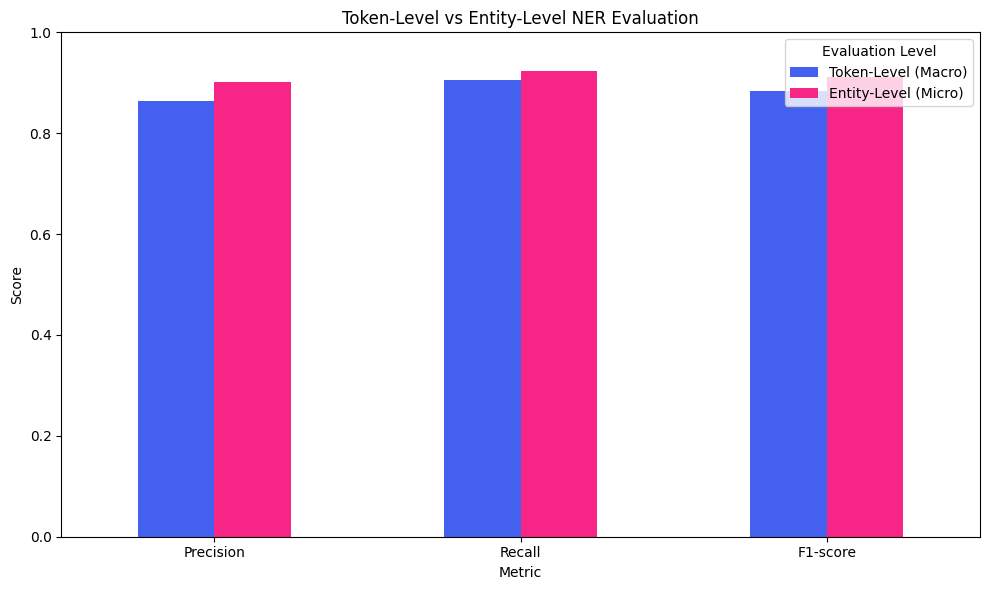

In [20]:

comparison_df = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score"],
    "Token-Level (Macro)": [
        token_precision,
        token_recall,
        token_f1
    ],
    "Entity-Level (Micro)": [
        ner_precision,
        ner_recall,
        ner_f1
    ]
})

display(comparison_df.round(4))

comparison_df.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6),
    rot=0,
    color=["#4361EE", "#F72585"]
)

plt.title("Token-Level vs Entity-Level NER Evaluation")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Evaluation Level")

plt.tight_layout()
plt.show()


### Comparison Between Token-Level and Entity-Level Evaluation

The experiment evaluates Named Entity Recognition performance at two different levels:

- **Token-level evaluation:** Measures the correctness of individual BIO tags.
- **Entity-level evaluation:** Measures the correctness of complete named entities, including their boundaries and categories.

#### Experimental Results

| Metric | Token-Level (Macro) | Entity-Level (Micro) |
|---|---:|---:|
| Precision | 0.8641 | 0.9010 |
| Recall | 0.9049 | 0.9236 |
| F1-score | 0.8830 | 0.9122 |

#### Interpretation

The entity-level Precision, Recall, and F1-score are numerically higher than the corresponding token-level macro-averaged metrics.

However, the two evaluation methods measure different units and use different averaging strategies.

Token-level macro averaging assigns equal importance to each entity-related BIO tag, regardless of frequency.

Entity-level micro averaging aggregates correctly predicted, missed, and incorrectly predicted complete entities across all entity categories.

Consequently, the numerical difference between the scores should not be interpreted as evidence that entity-level evaluation is inherently easier.

#### Why Entity-Level Evaluation Matters

Consider a two-token entity such as "New York."

If the model correctly labels "New" but incorrectly labels "York," the token-level evaluation gives partial credit.

Under strict entity-level evaluation, the complete entity is considered incorrect because its boundaries do not match the reference.

This makes entity-level evaluation particularly relevant for information extraction applications.

#### Conclusion

Both evaluation approaches provide useful information.

Token-level metrics help identify errors in individual BIO tags, while entity-level metrics measure the quality of complete entity extraction.

For Named Entity Recognition, strict entity-level F1-score is generally the more appropriate primary performance metric.

,Precision,Recall,F1-score
PER,0.9686,0.9611,0.9648
ORG,0.8769,0.9048,0.8906
LOC,0.9237,0.9437,0.9336
MISC,0.7500,0.8265,0.7864


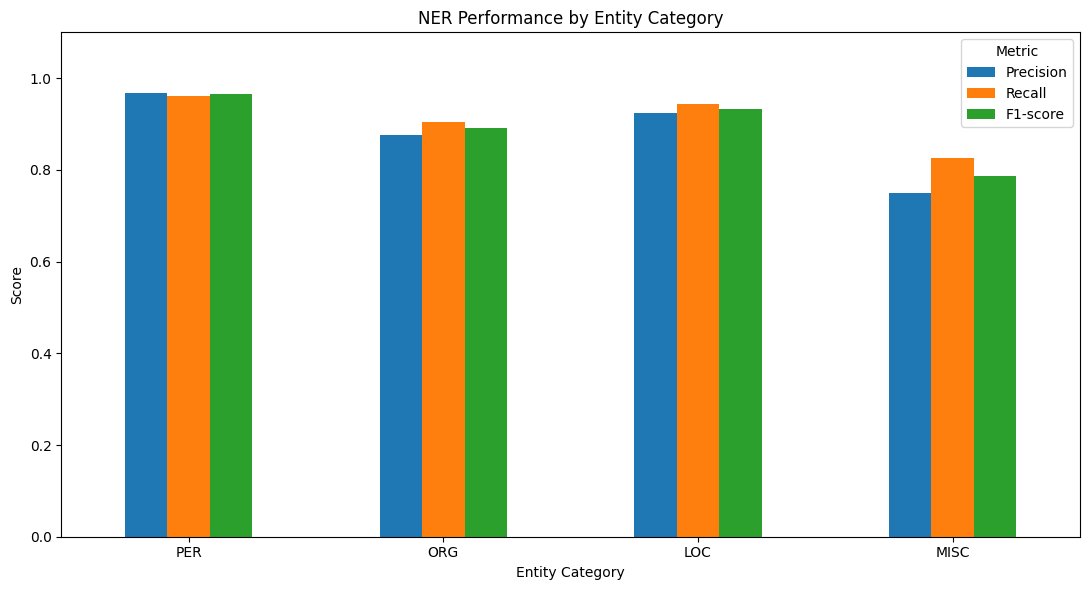

In [21]:

from seqeval.metrics import classification_report as entity_report

report_dict = entity_report(
    ner_true,
    ner_pred,
    mode="strict",
    scheme=IOB2,
    output_dict=True,
    zero_division=0
)

entity_types = ["PER", "ORG", "LOC", "MISC"]

entity_results = pd.DataFrame({
    entity_type: {
        "Precision": report_dict[entity_type]["precision"],
        "Recall": report_dict[entity_type]["recall"],
        "F1-score": report_dict[entity_type]["f1-score"]
    }
    for entity_type in entity_types
}).T

display(entity_results.round(4))

entity_results.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("NER Performance by Entity Category")
plt.xlabel("Entity Category")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend(title="Metric")

plt.tight_layout()
plt.show()


### Entity-Level Performance by Category

The entity-level classification report provides a detailed evaluation of the model across the four named entity categories.

#### Experimental Results

| Entity Category | Precision | Recall | F1-score |
|---|---:|---:|---:|
| PER | 0.9686 | 0.9611 | 0.9648 |
| ORG | 0.8769 | 0.9048 | 0.8906 |
| LOC | 0.9237 | 0.9437 | 0.9336 |
| MISC | 0.7500 | 0.8265 | 0.7864 |

#### 1. Person Entities (PER)

Person entities achieve the highest F1-score at **96.48%**.

The high Precision and Recall indicate that the model is effective at recognizing personal names with correct entity boundaries.

#### 2. Location Entities (LOC)

Location entities achieve an F1-score of **93.36%**.

The Recall of 94.37% indicates that most reference location entities are successfully identified.

However, some confusion occurs between locations and organizations, as observed in the token-level confusion matrix.

#### 3. Organization Entities (ORG)

Organization entities achieve an F1-score of **89.06%**.

The model performs well overall, although some organization names are incorrectly classified as locations or other entity categories.

#### 4. Miscellaneous Entities (MISC)

Miscellaneous entities achieve the lowest F1-score at **78.64%**.

The Precision of 75.00% indicates that a relatively larger proportion of predicted miscellaneous entities are incorrect.

This category may be more challenging because it includes a diverse range of named entities that do not belong to the person, organization, or location categories.

#### Comparative Interpretation

The results show the following ranking by F1-score:

1. PER: 96.48%
2. LOC: 93.36%
3. ORG: 89.06%
4. MISC: 78.64%

The model demonstrates particularly strong performance on person and location entities.

Miscellaneous entities represent the most challenging category in this experiment.

#### Conclusion

The category-level analysis reveals that overall entity-level F1-score can hide important differences between entity types.

Evaluating each category separately is therefore essential for identifying model strengths and weaknesses.

Total incorrectly labeled tokens: 141

Errors by reference BIO tag:
True Tag
O         57
B-ORG     20
B-MISC    14
I-ORG     14
B-LOC     13
I-MISC    11
B-PER      9
I-LOC      2
I-PER      1
Name: count, dtype: int64

Example tagging errors:


,Sentence ID,Token,True Tag,Predicted Tag
0,8,PREMIER,I-MISC,O
1,8,DIVISION,I-MISC,O
2,18,Yakomas,B-MISC,B-ORG
3,18,Patasse,B-PER,B-LOC
4,18,Baya,B-MISC,B-LOC
5,22,Balkan,B-LOC,B-ORG
6,37,U.S.,B-LOC,B-MISC
7,37,Amateur,O,I-MISC
8,44,DOWNHILL,O,I-MISC
9,54,Czech,B-LOC,B-MISC


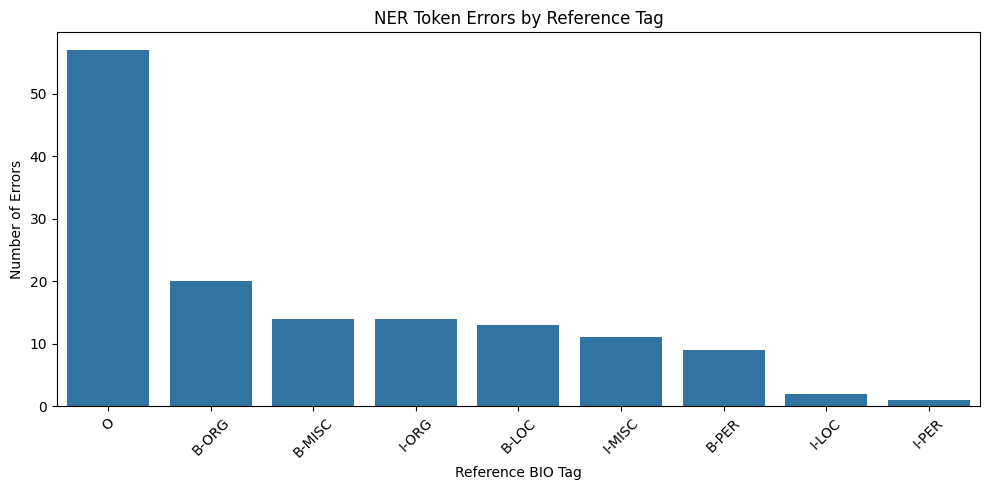

In [22]:

# Collect incorrectly predicted tokens
ner_errors = []

for sentence_id, (tokens, true_tags, pred_tags) in enumerate(
    zip(ner_tokens, ner_true, ner_pred)
):

    for token, true_tag, pred_tag in zip(
        tokens, true_tags, pred_tags
    ):

        if true_tag != pred_tag:
            ner_errors.append({
                "Sentence ID": sentence_id,
                "Token": token,
                "True Tag": true_tag,
                "Predicted Tag": pred_tag
            })

errors_df_ner = pd.DataFrame(ner_errors)

print("Total incorrectly labeled tokens:", len(errors_df_ner))

print("\nErrors by reference BIO tag:")
print(errors_df_ner["True Tag"].value_counts())

print("\nExample tagging errors:")
display(errors_df_ner.head(20))

plt.figure(figsize=(10, 5))

sns.countplot(
    data=errors_df_ner,
    x="True Tag",
    order=errors_df_ner["True Tag"].value_counts().index
)

plt.title("NER Token Errors by Reference Tag")
plt.xticks(rotation=45)
plt.xlabel("Reference BIO Tag")
plt.ylabel("Number of Errors")

plt.tight_layout()
plt.show()


### Error Analysis

Error analysis provides additional insight into the limitations of the pretrained BERT Named Entity Recognition model.

In this experiment, the model incorrectly labeled **141 out of 6,759 tokens**, corresponding to approximately 2.09% of all evaluated tokens.

#### 1. Error Distribution by Reference Tag

The errors are distributed as follows:

| Reference BIO Tag | Number of Errors |
|---|---:|
| O | 57 |
| B-ORG | 20 |
| B-MISC | 14 |
| I-ORG | 14 |
| B-LOC | 13 |
| I-MISC | 11 |
| B-PER | 9 |
| I-LOC | 2 |
| I-PER | 1 |
| **Total** | **141** |

The largest absolute number of errors occurs for the non-entity label O.

However, O is also the most frequent tag in the dataset, so its absolute error count should not be interpreted as the highest error rate.

Miscellaneous and organization-related tags show notable classification difficulties.

#### 2. Organization and Location Confusion

Several errors involve confusion between organizations and locations.

For example:

- "Balkan" was labeled B-LOC in the reference but predicted as B-ORG.
- "UK" was labeled B-LOC but predicted as B-ORG.
- "Iran" was labeled B-MISC but predicted as B-LOC.

These examples illustrate how named entities can be difficult to classify when their meaning depends on context or dataset-specific annotation conventions.

#### 3. Miscellaneous Entity Errors

The model also makes errors involving miscellaneous entities.

For example:

- "PREMIER" was labeled I-MISC but predicted as O.
- "DIVISION" was labeled I-MISC but predicted as O.
- "Yakomas" was labeled B-MISC but predicted as B-ORG.

These errors indicate that the model sometimes fails to recognize miscellaneous entities or assigns them to other categories.

#### 4. False Entity Detection

Some tokens labeled O were incorrectly predicted as parts of named entities.

For example, the tokens "One," "Global," "Depository," and "Receipt" were predicted as organization-related tags despite having O reference labels.

This demonstrates that the model may incorrectly identify ordinary words as named entities.

#### 5. Possible Causes of Errors

Several factors may contribute to the observed errors:

- **Contextual ambiguity:** The same word may represent different entity types depending on its context.
- **Entity boundary errors:** The model may identify only part of a multi-token entity.
- **Annotation conventions:** CoNLL-2003 labels may differ from intuitive entity classifications in certain contexts.
- **Miscellaneous entity diversity:** The MISC category contains heterogeneous entity types.
- **Limited context:** Short sentences may provide insufficient information for reliable entity classification.

These explanations are plausible hypotheses rather than experimentally confirmed causes.

#### Conclusion

The error analysis confirms that BERT performs well overall but encounters difficulties with miscellaneous entities, organization-location distinctions, and entity boundaries.

Examining individual errors provides a more detailed understanding of model behavior than aggregate evaluation metrics alone.

### Conclusion: Named Entity Recognition Evaluation

This experiment evaluated a pretrained BERT-based Named Entity Recognition model on 500 real sentences from the CoNLL-2003 test dataset.

The model was evaluated using token-level and entity-level metrics, including Accuracy, Precision, Recall, F1-score, confusion matrices, and error analysis.

#### Summary of Experimental Results

| Evaluation Metric | Result |
|---|---:|
| Token-level Accuracy | 97.91% |
| Token-level Macro Precision | 86.41% |
| Token-level Macro Recall | 90.49% |
| Token-level Macro F1-score | 88.30% |
| Entity-level Precision | 90.10% |
| Entity-level Recall | 92.36% |
| Entity-level F1-score | 91.22% |

#### Main Findings

The pretrained BERT model demonstrated strong Named Entity Recognition performance on the selected CoNLL-2003 test sentences.

The token-level accuracy of 97.91% indicates that the vast majority of BIO tags were correctly predicted.

However, the high frequency of non-entity tokens highlights the limitations of relying exclusively on token-level accuracy.

The entity-level F1-score of 91.22% demonstrates that the model can accurately identify complete named entities, including their boundaries and categories.

The category-level evaluation revealed particularly strong performance for person and location entities.

Miscellaneous entities achieved lower scores, indicating that this category remains more challenging.

The confusion matrix and error analysis also identified errors involving entity boundaries and confusion between organizations, locations, and miscellaneous entities.

#### Experimental Limitations

Several limitations should be considered:

1. Only 500 sentences from the CoNLL-2003 test split were evaluated.
2. The experiment used one pretrained BERT model without additional fine-tuning.
3. Word-level predictions were obtained from the first subword token.
4. The evaluation used strict IOB2 entity matching.
5. The results reflect performance on CoNLL-2003 and may not generalize to other domains or languages.

#### Final Conclusion

This experiment demonstrates the importance of selecting evaluation metrics that reflect the structure of the NLP task.

Token-level metrics provide useful information about individual label predictions, while entity-level metrics evaluate the correctness of complete named entities.

Combining both approaches with category-specific analysis and error inspection provides a more comprehensive assessment of NER performance.

Overall, the pretrained BERT model achieved strong performance on the selected CoNLL-2003 test subset.

The next experiment will focus on machine translation evaluation using a real pretrained translation model and reference translations.

## Part 3: Machine Translation Evaluation

### 3.1 Introduction

Machine Translation (MT) is a Natural Language Processing task that automatically translates text from one language into another while attempting to preserve its original meaning.

Unlike text classification and sequence labeling, machine translation is a text generation task. Therefore, its evaluation requires metrics that assess the similarity between generated translations and human reference translations.

### Experimental Objective

The objective of this experiment is to evaluate the translation quality of a real pretrained MarianMT model on English-to-French sentence pairs.

The experiment includes:

1. Loading a real parallel translation dataset.
2. Exploring source and reference sentence characteristics.
3. Loading a pretrained English-to-French MarianMT model.
4. Generating French translations from English sentences.
5. Comparing model translations with human reference translations.
6. Computing BLEU, METEOR, chrF, and TER.
7. Visualizing translation quality.
8. Analyzing translation errors and metric limitations.

### Evaluation Metrics

**BLEU (Bilingual Evaluation Understudy):** Measures modified word n-gram precision with a brevity penalty.

**METEOR:** Evaluates translation similarity using word alignment, Precision, Recall, and fragmentation penalties.

**chrF:** Measures character n-gram similarity between generated and reference translations.

**TER (Translation Edit Rate):** Estimates the number of edits needed to transform a generated translation into a reference translation.

For BLEU, METEOR, and chrF, higher scores generally indicate better reference-based translation similarity.

For TER, lower scores indicate less editing effort relative to the reference.

### Experimental Setup

- **Translation direction:** English to French
- **Model:** `Helsinki-NLP/opus-mt-en-fr`
- **Dataset:** OPUS Books (English–French)
- **Sample size:** 200 sentence pairs
- **Inference:** Pretrained model without additional fine-tuning
- **Environment:** Google Colab

The evaluation will use real model-generated translations and existing reference translations rather than manually simulated outputs.

In [23]:

!pip -q install -U transformers datasets sentencepiece sacrebleu nltk pandas numpy matplotlib seaborn accelerate

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from tqdm.auto import tqdm

import sacrebleu
from nltk.translate.meteor_score import meteor_score

nltk.download("wordnet")
nltk.download("omw-1.4")

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Environment ready for machine translation evaluation!")


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Unzipping corpora/wordnet.zip.
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Unzipping corpora/omw-1.4.zip.


Device: cpu
Environment ready for machine translation evaluation!


In [24]:

# Load the real OPUS Books English-French dataset
mt_dataset = load_dataset(
    "Helsinki-NLP/opus_books",
    "en-fr",
    split="train"
)

print("Original dataset size:", len(mt_dataset))
print("Dataset features:", mt_dataset.features)

# Select a reproducible evaluation sample
mt_sample = (
    mt_dataset
    .shuffle(seed=SEED)
    .select(range(200))
)

# Extract English sources and French references
source_texts = [
    example["translation"]["en"]
    for example in mt_sample
]

reference_texts = [
    example["translation"]["fr"]
    for example in mt_sample
]

mt_df = pd.DataFrame({
    "English Source": source_texts,
    "French Reference": reference_texts
})

print("\nSelected sentence pairs:", len(mt_df))

display(mt_df.head(10))


README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-fr/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

en-fr/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/127085 [00:00<?, ? examples/s]

Original dataset size: 127085
Dataset features: {'id': Value('string'), 'translation': Translation(languages=['en', 'fr'])}

Selected sentence pairs: 200


,English Source,French Reference
0,"""Not if it were my own brother!"" cried d’Artag...","«Non, fût-ce mon frère!» s'écria d'Artagnan co..."
1,"""Mr. Conseil put one over on me!""",Monsieur Conseil qui me fait poser !
2,What sister would think herself at liberty to ...,"Cependant si elles croyaient qu’il m’aime, ell..."
3,"""It is impossible a gentleman could have writt...","«Mon Dieu! dit-elle, saurait-il...» Et elle s'..."
4,The mere fact that solid men should patronize ...,"Ce simple fait, que des personnages considérab..."
5,"Cécile did not displease him, and he was quite...","Cécile ne lui déplaisait pas, et il voulait bi..."
6,I can see him as he was in those days with gre...,"Je me le rappelle encore, tel qu'il était en c..."
7,"""You have understood me, then, dear Monsieur d...","-- Vous m'avez donc comprise, cher monsieur d'..."
8,"This sort of wound that lived upon him, which ...","Cette sorte de blessure vivant sur lui, se rév..."
9,"I am impatient to succeed.""",Il me tarde de réussir. »


### Dataset Description

The experiment uses the English–French subset of the OPUS Books parallel corpus.

The dataset contains 127,085 English–French sentence pairs, consisting of English source texts and corresponding French reference translations.

A reproducible subset of 200 sentence pairs was selected using a fixed random seed of 42.

| Property | Value |
|---|---|
| Dataset | OPUS Books |
| Language pair | English–French |
| Original dataset size | 127,085 sentence pairs |
| Evaluation sample | 200 sentence pairs |
| Random seed | 42 |
| Source language | English |
| Target language | French |

The dataset contains literary text, including dialogue, descriptive passages, and narrative sentences.

These texts may contain complex sentence structures, idiomatic expressions, and stylistic variations.

The French reference translations provide a basis for evaluating the output of the pretrained MarianMT model.

**Experimental limitation:** Since MarianMT was trained using OPUS resources, overlap between the model's training data and the selected evaluation corpus cannot be ruled out. Therefore, the sample should not be treated as a guaranteed unseen test set.

English Sentence Length Statistics:


count    200.00000
mean      23.38000
std       18.56851
min        1.00000
25%       10.00000
50%       20.00000
75%       32.00000
max      134.00000
Name: English Length, dtype: float64


French Sentence Length Statistics:


count    200.000000
mean      22.615000
std       17.700092
min        1.000000
25%        9.750000
50%       18.000000
75%       32.250000
max      129.000000
Name: French Length, dtype: float64

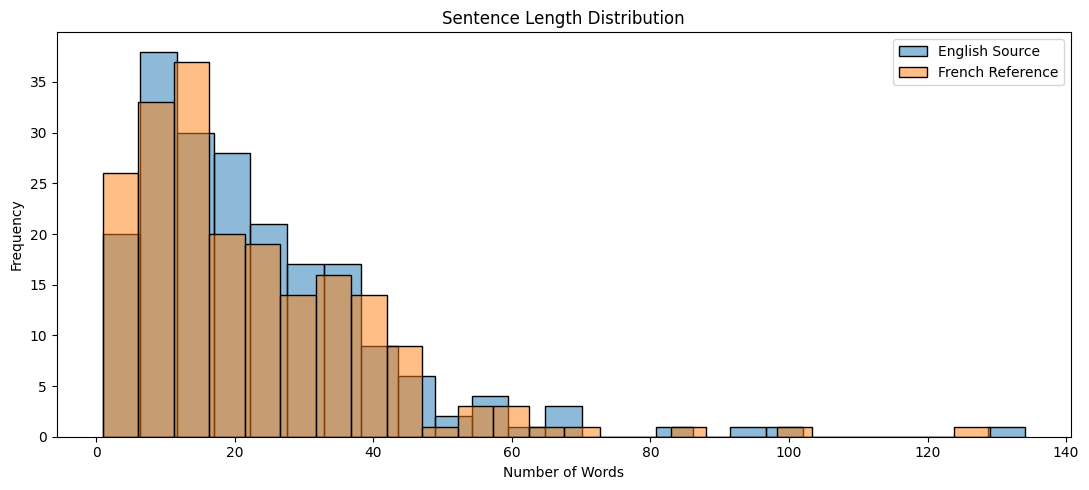


Example parallel sentence:
English: "Not if it were my own brother!" cried d’Artagnan, as if carried away by his enthusiasm.
French: «Non, fût-ce mon frère!» s'écria d'Artagnan comme emporté par l'enthousiasme.


In [25]:

# Calculate source and reference lengths
mt_df["English Length"] = (
    mt_df["English Source"]
    .apply(lambda x: len(x.split()))
)

mt_df["French Length"] = (
    mt_df["French Reference"]
    .apply(lambda x: len(x.split()))
)

print("English Sentence Length Statistics:")
display(mt_df["English Length"].describe())

print("\nFrench Sentence Length Statistics:")
display(mt_df["French Length"].describe())

# Visualize sentence length distributions
plt.figure(figsize=(11, 5))

sns.histplot(
    mt_df["English Length"],
    bins=25,
    label="English Source",
    alpha=0.5
)

sns.histplot(
    mt_df["French Length"],
    bins=25,
    label="French Reference",
    alpha=0.5
)

plt.title("Sentence Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

print("\nExample parallel sentence:")
print("English:", mt_df.iloc[0]["English Source"])
print("French:", mt_df.iloc[0]["French Reference"])


### Dataset Exploration and Analysis

The selected dataset contains 200 English source sentences and their corresponding French reference translations.

#### Sentence Length Statistics

| Statistic | English Source | French Reference |
|---|---:|---:|
| Minimum | 1 | 1 |
| Mean | 23.38 | 22.62 |
| Median | 20 | 18 |
| Maximum | 134 | 129 |
| Standard deviation | 18.57 | 17.70 |

#### Distribution Analysis

The sentence-length histogram shows that most English and French sentences contain fewer than approximately 40 words.

Both distributions are positively skewed, with a smaller number of long sentences extending beyond 100 words.

The average English sentence contains 23.38 words, compared with 22.62 words for the French reference.

This difference is relatively small, suggesting that the source and reference texts have broadly comparable lengths in this sample.

However, similar sentence lengths do not necessarily imply equivalent meaning or translation quality.

#### Linguistic Characteristics

The selected sentence pairs include literary dialogue, descriptive language, and narrative passages.

For example, the dataset contains sentences involving characters such as d'Artagnan and Conseil.

Literary translation can be challenging because meaning may be expressed through idiomatic constructions, stylistic choices, and context-dependent expressions.

#### Conclusion

The dataset provides a varied collection of sentence lengths and literary constructions for evaluating machine translation.

The presence of long sentences and stylistically complex language may influence translation quality, making sentence-level analysis important in addition to corpus-level metrics.

In [26]:

MT_MODEL_NAME = "Helsinki-NLP/opus-mt-en-fr"

mt_tokenizer = AutoTokenizer.from_pretrained(
    MT_MODEL_NAME
)

mt_model = AutoModelForSeq2SeqLM.from_pretrained(
    MT_MODEL_NAME
)

mt_model.to(device)
mt_model.eval()

print("Model loaded successfully!")
print("Model:", MT_MODEL_NAME)

print(
    "Number of model parameters:",
    sum(p.numel() for p in mt_model.parameters())
)


config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  301MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Model loaded successfully!
Model: Helsinki-NLP/opus-mt-en-fr
Number of model parameters: 75133952


In [27]:

batch_size = 8
generated_translations = []

mt_model.eval()

for start in tqdm(
    range(0, len(source_texts), batch_size),
    desc="Generating French translations"
):

    batch_texts = source_texts[
        start:start + batch_size
    ]

    inputs = mt_tokenizer(
        batch_texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=512
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():

        generated_ids = mt_model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=4,
            early_stopping=True
        )

    translations = mt_tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )

    generated_translations.extend(translations)

mt_df["Generated Translation"] = generated_translations

print("Total translations generated:", len(generated_translations))

display(
    mt_df[[
        "English Source",
        "French Reference",
        "Generated Translation"
    ]].head(10)
)


Generating French translations:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Total translations generated: 200


,English Source,French Reference,Generated Translation
0,"""Not if it were my own brother!"" cried d’Artag...","«Non, fût-ce mon frère!» s'écria d'Artagnan co...",– Pas si c'était mon propre frère ! s'écria d-...
1,"""Mr. Conseil put one over on me!""",Monsieur Conseil qui me fait poser !,"""M. Conseil en a mis un sur moi !"""
2,What sister would think herself at liberty to ...,"Cependant si elles croyaient qu’il m’aime, ell...","Quelle sœur se croirait libre de le faire, à m..."
3,"""It is impossible a gentleman could have writt...","«Mon Dieu! dit-elle, saurait-il...» Et elle s'...","""Il est impossible qu'un gentleman ait écrit u..."
4,The mere fact that solid men should patronize ...,"Ce simple fait, que des personnages considérab...",Le simple fait que des hommes solides doivent ...
5,"Cécile did not displease him, and he was quite...","Cécile ne lui déplaisait pas, et il voulait bi...","Cécile ne lui déplaisait pas, et il était tout..."
6,I can see him as he was in those days with gre...,"Je me le rappelle encore, tel qu'il était en c...",Je peux le voir tel qu'il était à cette époque...
7,"""You have understood me, then, dear Monsieur d...","-- Vous m'avez donc comprise, cher monsieur d'...","-- Vous m'avez donc compris, cher Monsieur d'A..."
8,"This sort of wound that lived upon him, which ...","Cette sorte de blessure vivant sur lui, se rév...","Ce genre de blessure qui vivait sur lui, qui e..."
9,"I am impatient to succeed.""",Il me tarde de réussir. »,"Je suis impatient de réussir."""


### Analysis of MarianMT Generated Translations

The pretrained MarianMT model generated 200 French translations from English source sentences using beam search with four beams.

The generated translations were compared with the corresponding human reference translations from the OPUS Books dataset.

#### Initial Observations

The displayed examples show that the model produces French sentences with recognizable vocabulary and grammatical structure.

However, the generated translations do not always match the wording of the human references.

For example, the English sentence:

**"I am impatient to succeed."**

has the following translations:

- **Human reference:** "Il me tarde de réussir."
- **Model translation:** "Je suis impatient de réussir."

Both French expressions convey a similar central meaning, although their phrasing differs.

This demonstrates an important limitation of reference-based machine translation metrics: a valid translation may receive a lower score when its wording differs from the reference.

#### Translation Errors

Other examples reveal possible translation difficulties.

For the sentence:

**"Mr. Conseil put one over on me!"**

the generated translation is:

**"M. Conseil en a mis un sur moi !"**

The English expression "put one over on me" is idiomatic and means that someone deceived or tricked the speaker.

The generated French sentence appears to translate the expression too literally, producing an unnatural result.

This illustrates the difficulty of translating idiomatic expressions using automatic translation models.

#### Conclusion

The initial examples demonstrate that MarianMT can generate plausible French translations, but translation quality varies depending on sentence structure, idiomatic language, and stylistic requirements.

These observations motivate the use of several complementary evaluation metrics and detailed sentence-level error analysis.

In [28]:

# Corpus-level BLEU
bleu_result = sacrebleu.corpus_bleu(
    generated_translations,
    [reference_texts]
)

# Corpus-level chrF
chrf_result = sacrebleu.corpus_chrf(
    generated_translations,
    [reference_texts]
)

# Corpus-level TER
ter_result = sacrebleu.corpus_ter(
    generated_translations,
    [reference_texts]
)

# Sentence-level METEOR, averaged across the corpus
meteor_values = []

for hypothesis, reference in zip(
    generated_translations,
    reference_texts
):

    score = meteor_score(
        [reference.split()],
        hypothesis.split()
    )

    meteor_values.append(score)

meteor_mean = np.mean(meteor_values)

# Store results
mt_results = {
    "BLEU": bleu_result.score,
    "METEOR": meteor_mean,
    "chrF": chrf_result.score,
    "TER": ter_result.score
}

print("=== MarianMT Evaluation Results ===")

print(f"BLEU:   {mt_results['BLEU']:.4f}")
print(f"METEOR: {mt_results['METEOR']:.4f}")
print(f"chrF:   {mt_results['chrF']:.4f}")
print(f"TER:    {mt_results['TER']:.4f}")

print("\nMetric signatures:")
print("BLEU:", bleu_result)
print("chrF:", chrf_result)
print("TER:", ter_result)


=== MarianMT Evaluation Results ===
BLEU:   20.3004
METEOR: 0.3788
chrF:   48.2011
TER:    73.2036

Metric signatures:
BLEU: BLEU = 20.30 48.4/25.2/15.0/9.3 (BP = 1.000 ratio = 1.041 hyp_len = 5400 ref_len = 5189)
chrF: chrF2 = 48.20
TER: TER = 73.20


### Machine Translation Evaluation Results

The MarianMT model was evaluated on 200 English–French sentence pairs using four reference-based evaluation metrics.

#### Experimental Results

| Metric | Score | Preferred Direction |
|---|---:|---|
| BLEU | 20.3004 | Higher is better |
| METEOR | 0.3788 | Higher is better |
| chrF | 48.2011 | Higher is better |
| TER | 73.2036 | Lower is better |

These metrics use different scales and evaluation methods, so their numerical values should not be directly compared.

#### 1. BLEU Score

The model achieved a corpus-level BLEU score of **20.30**.

BLEU evaluates the overlap of word n-grams between generated translations and human references, applying a brevity penalty when necessary.

The score indicates that the generated translations have limited exact word-sequence overlap with the reference translations.

The detailed BLEU output shows decreasing n-gram precision:

| N-gram Order | Precision |
|---|---:|
| Unigrams | 48.4% |
| Bigrams | 25.2% |
| Trigrams | 15.0% |
| Four-grams | 9.3% |

The decrease in precision for longer n-grams indicates that exact phrase-level matches are less frequent than individual word matches.

The brevity penalty is 1.000, meaning that no brevity penalty was applied at the corpus level.

#### 2. METEOR Score

The average METEOR score is **0.3788**.

METEOR evaluates translation similarity through word alignment, combining Precision, Recall, and a penalty for fragmented matches.

The score indicates partial lexical and structural correspondence between the generated translations and human references.

However, the implementation used in this experiment tokenizes sentences using whitespace splitting and applies the available NLTK matching resources. It should therefore be interpreted as a specific implementation of METEOR rather than a complete semantic evaluation of translation quality.

#### 3. chrF Score

The model achieved a chrF score of **48.20**.

chrF evaluates character n-gram similarity rather than relying exclusively on complete word matches.

This makes it useful for languages with morphological variation and different word forms.

The result indicates a measurable degree of character-level overlap between the generated French translations and the references.

However, character similarity does not guarantee that the translation preserves the original meaning.

#### 4. TER Score

The model achieved a TER score of **73.20**.

TER measures the edit operations required to transform generated translations into reference translations, normalized by reference length.

A score of 73.20 indicates a relatively high amount of reference-oriented editing.

This does not necessarily mean that 73.20% of the translations are incorrect.

Valid paraphrases and alternative expressions can increase TER even when the generated translation preserves the intended meaning.

#### 5. Complementary Interpretation

The four metrics evaluate different aspects of translation quality.

- BLEU focuses on word n-gram precision.
- METEOR considers word alignment and Recall.
- chrF evaluates character-level similarity.
- TER measures the edits needed to match the reference.

The results indicate that MarianMT generates translations with partial reference overlap, but exact wording and phrase structure frequently differ from the human translations.

The literary nature of the dataset may contribute to these differences because multiple valid French translations can express the same English sentence.

#### Conclusion

The evaluation demonstrates that machine translation quality cannot be adequately described using a single metric.

Combining BLEU, METEOR, chrF, and TER provides a more comprehensive picture of reference-based translation similarity.

However, automatic metrics should be complemented by qualitative analysis to assess meaning preservation, fluency, and idiomatic correctness.

In [29]:

sentence_bleu = []
sentence_chrf = []
sentence_ter = []

for hypothesis, reference in zip(
    generated_translations,
    reference_texts
):
    bleu = sacrebleu.sentence_bleu(
        hypothesis,
        [reference]
    ).score

    chrf = sacrebleu.sentence_chrf(
        hypothesis,
        [reference]
    ).score

    ter = sacrebleu.sentence_ter(
        hypothesis,
        [reference]
    ).score

    sentence_bleu.append(bleu)
    sentence_chrf.append(chrf)
    sentence_ter.append(ter)

mt_df["BLEU"] = sentence_bleu
mt_df["METEOR"] = meteor_values
mt_df["chrF"] = sentence_chrf
mt_df["TER"] = sentence_ter

print("Sentence-Level Metric Statistics:")
display(
    mt_df[["BLEU", "METEOR", "chrF", "TER"]]
    .describe()
    .round(4)
)


Sentence-Level Metric Statistics:


,BLEU,METEOR,chrF,TER
count,200.0000,200.0000,200.0000,200.0000
mean,20.0285,0.3788,47.6567,74.3860
std,17.2349,0.2324,19.6751,31.3103
min,0.0000,0.0000,1.5723,7.1429
25%,6.6987,0.1891,36.3050,53.8462
50%,15.2969,0.4007,48.0188,69.8626
75%,28.8462,0.5426,60.9327,94.5833
max,86.6642,0.9375,100.0000,200.0000


### Sentence-Level Translation Metrics

Sentence-level evaluation provides a more detailed assessment of translation quality than corpus-level scores alone.

The four evaluation metrics were calculated individually for all 200 generated translations.

#### Experimental Results

| Statistic | BLEU | METEOR | chrF | TER |
|---|---:|---:|---:|---:|
| Mean | 20.0285 | 0.3788 | 47.6567 | 74.3860 |
| Standard deviation | 17.2349 | 0.2324 | 19.6751 | 31.3103 |
| Minimum | 0.0000 | 0.0000 | 1.5723 | 7.1429 |
| Median | 15.2969 | 0.4007 | 48.0188 | 69.8626 |
| Maximum | 86.6642 | 0.9375 | 100.0000 | 200.0000 |

#### Interpretation

**BLEU:** The average sentence-level BLEU score is 20.03, with a standard deviation of 17.23. This indicates considerable variation in exact word n-gram overlap across the evaluated sentences.

**METEOR:** The mean score is 0.3788, while the median is 0.4007. The wide range of values indicates that some translations share substantial lexical similarity with their references, whereas others have very little overlap.

**chrF:** The mean chrF score is 47.66, with a standard deviation of 19.68. This demonstrates substantial variation in character-level similarity across the dataset.

**TER:** The average TER score is 74.39, indicating a relatively high amount of editing required to match the reference translations. Some sentence-level TER scores exceed 100 because the number of edit operations can exceed the reference length.

#### Corpus-Level vs Sentence-Level Metrics

The average sentence-level BLEU score (20.03) differs slightly from the corpus-level BLEU score (20.30).

This difference is expected because corpus BLEU aggregates n-gram counts across the entire dataset before calculating the final score, whereas sentence-level BLEU scores are computed individually and then averaged.

The same distinction applies to corpus-level and sentence-level chrF and TER.

#### Conclusion

The sentence-level statistics demonstrate that translation quality varies substantially across the 200 evaluated sentences.

Aggregate metrics provide a useful overall summary, but sentence-level analysis is necessary to identify unusually strong or weak translation examples.

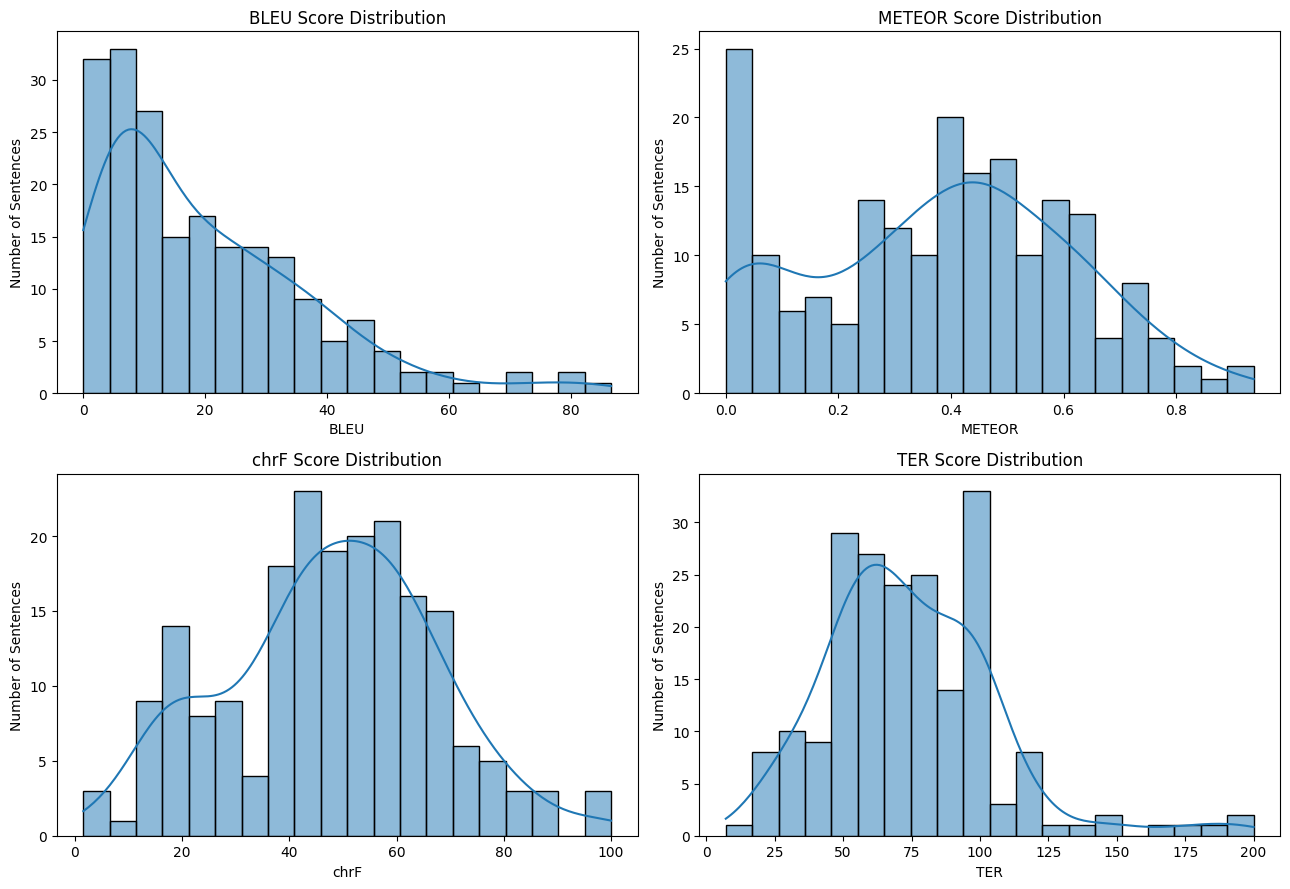

In [30]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = ["BLEU", "METEOR", "chrF", "TER"]

for ax, metric in zip(axes.flatten(), metrics):
    sns.histplot(
        mt_df[metric],
        bins=20,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{metric} Score Distribution")
    ax.set_xlabel(metric)
    ax.set_ylabel("Number of Sentences")

plt.tight_layout()
plt.show()


### Distribution of Translation Quality Scores

The histograms illustrate the distribution of BLEU, METEOR, chrF, and TER scores across the 200 generated translations.

#### BLEU Distribution

The BLEU distribution is positively skewed, with many sentences receiving relatively low scores.

Most values are concentrated below approximately 30, while a smaller number of translations achieve scores above 50.

This indicates that exact word n-gram overlap is relatively limited for many generated translations.

#### METEOR Distribution

METEOR scores are distributed across a broad range, with a concentration around 0.3–0.6 and a noticeable group of sentences receiving very low scores.

This suggests that some translations preserve substantial lexical correspondence with their references, while others differ considerably.

#### chrF Distribution

The chrF distribution is concentrated primarily between approximately 35 and 65.

Some translations achieve very high character-level similarity, while others receive scores close to zero.

This variation demonstrates that character-based evaluation can distinguish between translations with different degrees of textual similarity.

#### TER Distribution

TER values are concentrated mainly between approximately 40 and 105, with a smaller number of extreme values reaching 200.

Higher TER scores indicate that more edits are needed to transform generated translations into the corresponding references.

#### Overall Interpretation

The distributions demonstrate substantial variation in reference-based translation similarity.

No single metric captures every aspect of translation quality.

For example, a translation may preserve the meaning of the original sentence while using different vocabulary or sentence structure from the reference.

Therefore, the observed score distributions should be interpreted alongside qualitative translation examples.

#### Conclusion

The metric distributions confirm that MarianMT produces translations with varying degrees of similarity to the human references.

They also highlight the importance of combining corpus-level evaluation, sentence-level evaluation, and qualitative analysis.

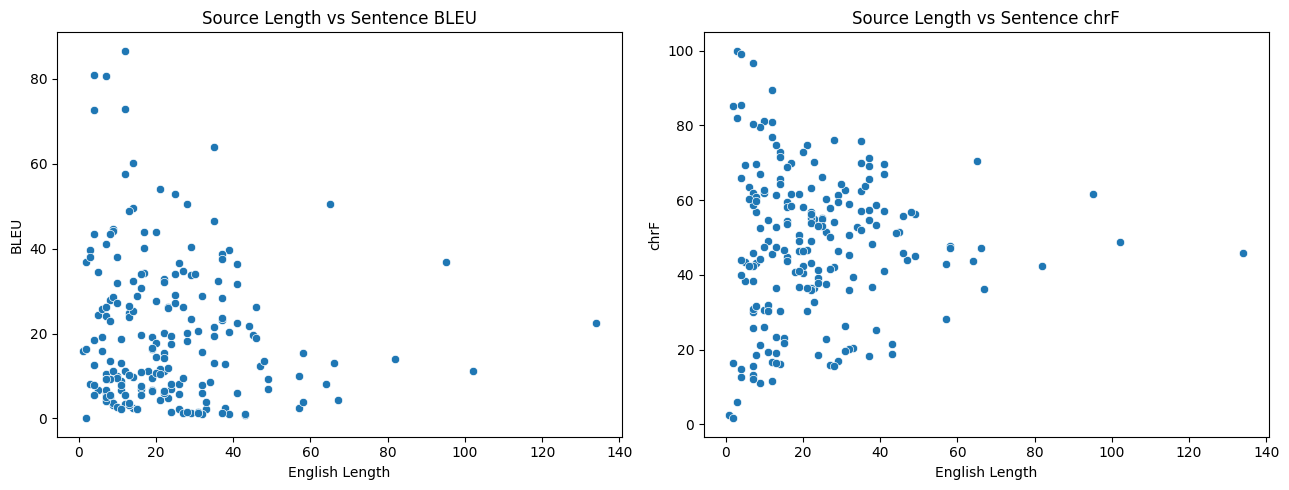

Correlation with Source Length:
English Length    1.0000
BLEU             -0.0807
chrF              0.0283
TER               0.0330
Name: English Length, dtype: float64


In [31]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=mt_df,
    x="English Length",
    y="BLEU",
    ax=axes[0]
)

axes[0].set_title("Source Length vs Sentence BLEU")

sns.scatterplot(
    data=mt_df,
    x="English Length",
    y="chrF",
    ax=axes[1]
)

axes[1].set_title("Source Length vs Sentence chrF")

plt.tight_layout()
plt.show()

print("Correlation with Source Length:")

print(
    mt_df[
        ["English Length", "BLEU", "chrF", "TER"]
    ].corr()["English Length"].round(4)
)


### Relationship Between Sentence Length and Translation Quality

This experiment investigates whether the length of an English source sentence is associated with its translation evaluation scores.

#### Experimental Correlations

| Variable | Correlation with Source Length |
|---|---:|
| BLEU | -0.0807 |
| chrF | 0.0283 |
| TER | 0.0330 |

#### Interpretation

**1. Source Length vs BLEU**

The Pearson correlation between source sentence length and BLEU is -0.0807.

This indicates a very weak negative linear relationship.

Longer sentences tend to have slightly lower BLEU scores in this sample, but the relationship is too weak to suggest a meaningful linear association.

**2. Source Length vs chrF**

The correlation between source length and chrF is 0.0283.

This value is close to zero, indicating virtually no linear relationship between source length and character-level translation similarity.

**3. Source Length vs TER**

The correlation between source length and TER is 0.0330.

This also indicates a negligible linear relationship.

#### Scatterplot Analysis

The scatterplots show considerable variation in BLEU and chrF scores, particularly among shorter sentences.

Some short sentences receive very high scores, while others receive scores close to zero.

Longer sentences also display variation, although fewer long examples are present in the selected sample.

#### Conclusion

The observed correlations provide little evidence of a strong linear relationship between English source sentence length and translation evaluation scores.

Translation quality, as measured by these reference-based metrics, appears to depend on factors beyond sentence length.

Potential factors include lexical choices, idiomatic expressions, sentence structure, reference wording, and source-reference alignment.

However, additional experiments would be required to determine their individual contributions.

In [32]:

columns = [
    "English Source",
    "French Reference",
    "Generated Translation",
    "BLEU",
    "METEOR",
    "chrF",
    "TER"
]

print("=== Highest BLEU Scores ===")

display(
    mt_df.nlargest(5, "BLEU")[columns]
    .round(4)
)

print("\n=== Lowest BLEU Scores ===")

display(
    mt_df.nsmallest(5, "BLEU")[columns]
    .round(4)
)


=== Highest BLEU Scores ===


,English Source,French Reference,Generated Translation,BLEU,METEOR,chrF,TER
20,Étienne had only time to parry the first blow ...,Étienne n'avait eu que le temps de parer le pr...,Étienne n'a eu que le temps de parer le premie...,86.6642,0.9269,89.4718,7.1429
128,"He speaks Danish perfectly.""",Il parle parfaitement le danois.,"Il parle parfaitement le danois.""",80.9107,0.7938,99.2184,20.0000
82,"""Is there immediate danger?"" murmured Mr. Mason.",«Y a-t-il un danger immédiat? murmura M. Mason.,-- Y a-t-il un danger immédiat? murmura M. Mason.,80.7056,0.8629,96.8104,25.0000
186,FOR SOME DAYS the Nautilus kept veering away f...,"Pendant quelques jours, le _Nautilus_ s'écarta...","Pendant quelques jours, le _Nautilus_ s'éloign...",72.8596,0.8212,76.8730,18.1818
76,"""No, a water machine.""","-- Non, une machine à eau.»","""Non, une machine à eau.""",72.5980,0.4991,85.3774,50.0000



=== Lowest BLEU Scores ===


,English Source,French Reference,Generated Translation,BLEU,METEOR,chrF,TER
171,Chapter 3,CHAPITRE III,Chapitre 3,0.0000,0.9375,1.5723,50.0000
73,"Or, rien au monde ne pouvait faire plus de pei...",Now nothing in the world was more capable of d...,"Or, rien au monde ne pouvait faire plus de pei...",0.9049,0.0223,21.4792,97.7778
50,"Au milieu de toutes ces injures, Clélia vint à...","In the midst of all this abuse, Clelia happene...","Au milieu de toutes ces blessures, Clélia vint...",1.0579,0.0000,20.1427,100.0000
90,Deux ou trois ans après cette grande époque de...,Two or three years after that great event in h...,Deux ou trois ans après cette grande époque de...,1.1209,0.0368,25.3355,100.0000
184,Puis tout à coup elle ajouta : « Non pas seule...,"Then suddenly she added: ""Not only silly; he m...",Puis tout à coup elle ajouta : « Non pas seule...,1.1245,0.0124,18.9303,107.5000


### Qualitative Analysis of Translation Examples

To better understand the model's performance, the five highest-scoring and five lowest-scoring translations were examined using sentence-level BLEU.

#### 1. Highest-Scoring Translations

The best-performing examples achieved BLEU scores ranging from approximately 72.60 to 86.66.

One example involves the English sentence:

**"He speaks Danish perfectly."**

The human reference and generated translation both use the French expression:

**"Il parle parfaitement le danois."**

The generated translation achieves a BLEU score of 80.91 and a chrF score of 99.22.

This example demonstrates that MarianMT can produce translations that closely match human reference wording.

Other high-scoring examples show similarly strong lexical and structural correspondence.

#### 2. Lowest-Scoring Translations

The lowest BLEU scores range from 0 to approximately 1.12.

However, inspection of the displayed examples reveals an important evaluation issue.

Some source-reference pairs appear to have reversed languages or inconsistent alignment.

For example, one record contains:

- **English Source:** "Chapter 3"
- **French Reference:** "CHAPITRE III"
- **Generated Translation:** "Chapitre 3"

Although the generated translation is understandable French, its BLEU score is zero because it does not share the required word n-grams with the reference.

Another displayed record contains French text in the English source column and English text in the French reference column.

This indicates that some examples may have incorrect translation direction or source-reference alignment.

#### 3. Implications for Evaluation

These observations are important because automatic translation metrics assume that the source and reference sentences form a valid parallel pair in the expected languages.

When this assumption is violated, a translation may receive an artificially low score even if the model generates a reasonable output.

Additionally, literary translations may use different but valid expressions, reducing exact lexical overlap.

#### 4. Dataset Quality Considerations

The observed examples suggest that the evaluation corpus should be checked for:

- Incorrect language direction.
- Misaligned source-reference pairs.
- Chapter headings and non-sentence fragments.
- Alternative valid translations with different wording.

These issues can influence BLEU, METEOR, chrF, and TER.

#### Conclusion

The qualitative analysis demonstrates that low automatic evaluation scores do not always indicate poor translation quality.

Some low-scoring examples reflect lexical differences, while others reveal possible dataset alignment or language-direction problems.

This highlights the importance of inspecting the evaluation data before drawing strong conclusions about machine translation performance.

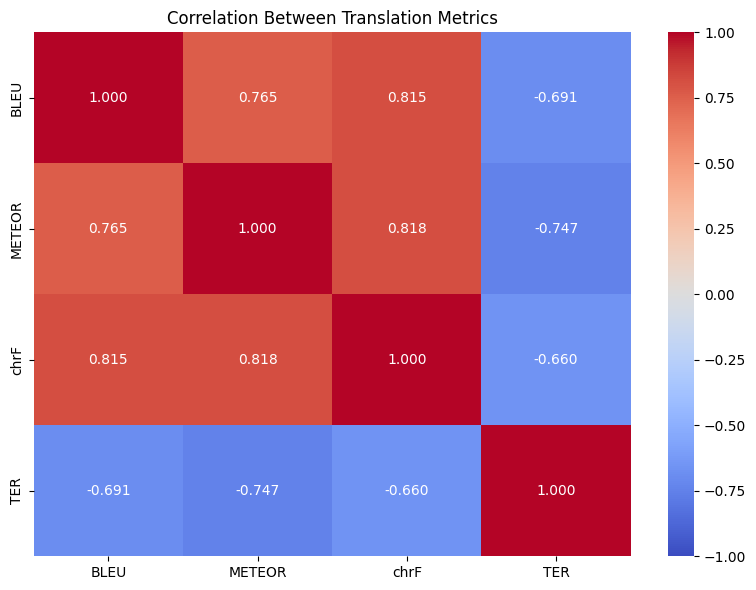

,BLEU,METEOR,chrF,TER
BLEU,1.0000,0.7655,0.8147,-0.6907
METEOR,0.7655,1.0000,0.8183,-0.7471
chrF,0.8147,0.8183,1.0000,-0.6599
TER,-0.6907,-0.7471,-0.6599,1.0000


In [33]:

metric_correlation = mt_df[
    ["BLEU", "METEOR", "chrF", "TER"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    metric_correlation,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Translation Metrics")

plt.tight_layout()
plt.show()

display(metric_correlation.round(4))


### Correlation Between Machine Translation Metrics

The correlation matrix examines the relationships between the four sentence-level translation evaluation metrics.

#### Experimental Results

| Metric Pair | Pearson Correlation |
|---|---:|
| BLEU – METEOR | 0.7655 |
| BLEU – chrF | 0.8147 |
| METEOR – chrF | 0.8183 |
| BLEU – TER | -0.6907 |
| METEOR – TER | -0.7471 |
| chrF – TER | -0.6599 |

#### Interpretation

**1. BLEU and METEOR**

The correlation of 0.7655 indicates a strong positive relationship.

Translations receiving higher BLEU scores generally also receive higher METEOR scores.

**2. BLEU and chrF**

The correlation of 0.8147 indicates a strong positive relationship.

This suggests that translations with greater word n-gram overlap also tend to have greater character n-gram similarity.

**3. METEOR and chrF**

The correlation of 0.8183 is the strongest positive relationship observed.

This indicates substantial agreement between the two metrics when ranking translations by reference-based similarity.

**4. TER and the Other Metrics**

TER is negatively correlated with BLEU, METEOR, and chrF.

This is expected because lower TER scores indicate fewer editing operations, while higher BLEU, METEOR, and chrF scores indicate greater reference similarity.

The strongest negative correlation is observed between METEOR and TER (-0.7471).

#### Overall Interpretation

The correlation matrix demonstrates that the four metrics capture related aspects of translation similarity.

However, none of the correlations is perfect.

This indicates that the metrics provide complementary information rather than identical evaluations.

#### Conclusion

The correlation analysis supports the use of multiple evaluation metrics for machine translation.

BLEU, METEOR, and chrF show strong positive associations, while TER is negatively associated with all three.

Combining these metrics provides a more comprehensive reference-based evaluation than relying on a single score.

### Conclusion: Machine Translation Evaluation

This experiment evaluated the pretrained Helsinki-NLP MarianMT model on 200 real English–French sentence pairs from the OPUS Books dataset.

The model generated French translations using beam search and was evaluated against human reference translations.

#### Summary of Corpus-Level Results

| Evaluation Metric | Result |
|---|---:|
| BLEU | 20.3004 |
| METEOR (Mean) | 0.3788 |
| chrF | 48.2011 |
| TER | 73.2036 |

#### Main Findings

The corpus-level BLEU score of 20.30 indicates limited exact word n-gram overlap between generated translations and human references.

The METEOR score of 0.3788 and chrF score of 48.20 demonstrate partial lexical and character-level correspondence.

The TER score of 73.20 indicates that substantial editing is required to reproduce the reference wording.

Sentence-level evaluation revealed considerable variation across the 200 examples.

The correlation analysis showed strong positive relationships between BLEU, METEOR, and chrF, while TER was negatively correlated with these metrics.

The analysis of sentence length revealed negligible linear correlations with BLEU, chrF, and TER.

Qualitative inspection showed that some translations preserve the intended meaning despite differing from the human reference.

Importantly, several low-scoring examples also revealed possible dataset alignment or language-direction problems.

#### Experimental Limitations

1. The evaluation used only 200 sentence pairs.
2. The dataset contains literary language that allows multiple valid translations.
3. Some examples appear to contain language-direction or alignment inconsistencies.
4. The model was evaluated without additional fine-tuning.
5. Only one human reference translation was available per sentence.
6. Automatic metrics cannot fully evaluate semantic accuracy, fluency, or stylistic appropriateness.
7. Potential overlap between OPUS Books and the model's training data cannot be ruled out.

#### Final Conclusion

This experiment demonstrates that evaluating machine translation requires multiple complementary metrics and careful qualitative analysis.

BLEU measures word n-gram overlap, METEOR evaluates word alignment, chrF measures character-level similarity, and TER estimates reference-oriented editing requirements.

Although MarianMT produces understandable French translations in several observed examples, the automatic scores reveal substantial differences from the human reference translations.

The findings also emphasize that evaluation quality depends not only on the translation model but also on the correctness and suitability of the reference dataset.

Overall, the experiment illustrates both the usefulness and the limitations of automatic machine translation evaluation metrics.

# Part 4: Comparative Analysis and Final Conclusion

## 4.1 Introduction

This project investigated the evaluation of three fundamental Natural Language Processing tasks using real pretrained transformer models and real annotated datasets.

The experiments covered:

1. **Text Classification:** Sentiment analysis using DistilBERT on IMDb movie reviews.
2. **Sequence Labeling:** Named Entity Recognition using BERT on the CoNLL-2003 dataset.
3. **Machine Translation:** English-to-French translation using MarianMT on the OPUS Books dataset.

Each experiment involved model inference, quantitative evaluation, visualization, and error analysis.

The primary objective of this comparative analysis is not to determine which model is universally better, but to understand how evaluation methods differ according to the structure and objectives of each NLP task.

The analysis focuses on:

- The nature of the predictions generated by each model.
- The evaluation metrics used for each task.
- The strengths and limitations of the observed results.
- The importance of class imbalance, entity boundaries, and reference translation quality.
- The role of qualitative error analysis in interpreting automatic metrics.

In [34]:

import pandas as pd

experiment_summary = pd.DataFrame({
    "Task": [
        "Sentiment Classification",
        "Named Entity Recognition",
        "Machine Translation"
    ],
    "Model": [
        "DistilBERT",
        "BERT NER",
        "MarianMT"
    ],
    "Dataset": [
        "IMDb",
        "CoNLL-2003",
        "OPUS Books"
    ],
    "Evaluation Samples": [
        500,
        500,
        200
    ],
    "Primary Metric": [
        "Accuracy",
        "Entity-level F1",
        "Corpus BLEU"
    ],
    "Primary Score": [
        0.8900,
        0.9122,
        20.3004
    ]
})

display(experiment_summary)


,Task,Model,Dataset,Evaluation Samples,Primary Metric,Primary Score
0,Sentiment Classification,DistilBERT,IMDb,500,Accuracy,0.8900
1,Named Entity Recognition,BERT NER,CoNLL-2003,500,Entity-level F1,0.9122
2,Machine Translation,MarianMT,OPUS Books,200,Corpus BLEU,20.3004


### 4.2 Overview of the Experimental Results

The three experiments used different pretrained transformer models, datasets, and evaluation methodologies.

| Task | Model | Dataset | Evaluation Sample | Main Result |
|---|---|---|---:|---|
| Sentiment Classification | DistilBERT | IMDb | 500 reviews | Accuracy: 89.00% |
| Named Entity Recognition | BERT NER | CoNLL-2003 | 500 sentences | Entity F1: 91.22% |
| Machine Translation | MarianMT | OPUS Books | 200 sentence pairs | BLEU: 20.30 |

The classification experiment predicts one sentiment label for each movie review.

The NER experiment predicts BIO tags for individual words and identifies complete named entities.

The machine translation experiment generates variable-length French sentences from English inputs.

These tasks have different prediction structures and therefore require different evaluation approaches.

**The reported scores must not be directly compared as percentages of the same underlying concept.**

For example, an accuracy of 89% and an entity-level F1-score of 91.22% measure different aspects of performance, while BLEU uses an entirely different evaluation methodology.

The comparison should therefore focus on the suitability, interpretation, and limitations of each metric rather than ranking the three models by their numerical scores.

In [35]:

classification_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value": [
        0.8900,
        0.9099,
        0.8618,
        0.8852,
        0.9537
    ]
})

ner_metrics = pd.DataFrame({
    "Metric": [
        "Token Accuracy",
        "Token Macro Precision",
        "Token Macro Recall",
        "Token Macro F1",
        "Entity Precision",
        "Entity Recall",
        "Entity F1"
    ],
    "Value": [
        0.9791,
        0.8641,
        0.9049,
        0.8830,
        0.9010,
        0.9236,
        0.9122
    ]
})

translation_metrics = pd.DataFrame({
    "Metric": [
        "BLEU",
        "METEOR",
        "chrF",
        "TER"
    ],
    "Value": [
        20.3004,
        0.3788,
        48.2011,
        73.2036
    ]
})

print("=== Classification Metrics ===")
display(classification_metrics)

print("\n=== NER Metrics ===")
display(ner_metrics)

print("\n=== Machine Translation Metrics ===")
display(translation_metrics)


=== Classification Metrics ===


,Metric,Value
0,Accuracy,0.8900
1,Precision,0.9099
2,Recall,0.8618
3,F1-score,0.8852
4,ROC-AUC,0.9537



=== NER Metrics ===


,Metric,Value
0,Token Accuracy,0.9791
1,Token Macro Precision,0.8641
2,Token Macro Recall,0.9049
3,Token Macro F1,0.8830
4,Entity Precision,0.9010
5,Entity Recall,0.9236
6,Entity F1,0.9122



=== Machine Translation Metrics ===


,Metric,Value
0,BLEU,20.3004
1,METEOR,0.3788
2,chrF,48.2011
3,TER,73.2036


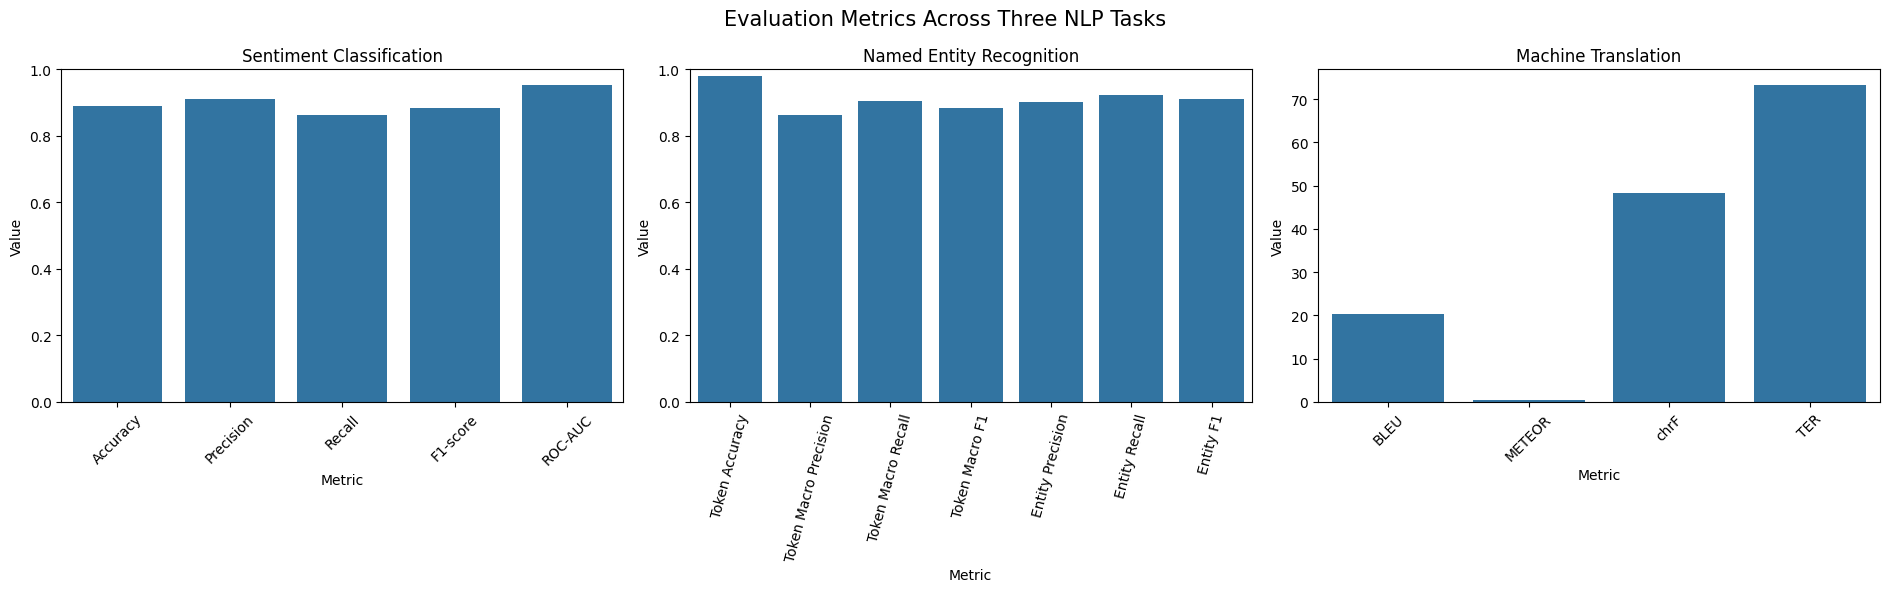

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# Classification metrics
sns.barplot(
    data=classification_metrics,
    x="Metric",
    y="Value",
    ax=axes[0]
)

axes[0].set_title("Sentiment Classification")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=45)

# NER metrics
sns.barplot(
    data=ner_metrics,
    x="Metric",
    y="Value",
    ax=axes[1]
)

axes[1].set_title("Named Entity Recognition")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=75)

# Translation metrics
sns.barplot(
    data=translation_metrics,
    x="Metric",
    y="Value",
    ax=axes[2]
)

axes[2].set_title("Machine Translation")
axes[2].tick_params(axis="x", rotation=45)

plt.suptitle(
    "Evaluation Metrics Across Three NLP Tasks",
    fontsize=15
)

plt.tight_layout()
plt.show()


### 4.3 Comparative Interpretation of Evaluation Metrics

The three visualizations summarize the quantitative results of the experiments.

#### Sentiment Classification

DistilBERT achieved:

- Accuracy: 89.00%
- Precision: 90.99%
- Recall: 86.18%
- F1-score: 88.52%
- ROC-AUC: 95.37%

The ROC-AUC score indicates strong discrimination between positive and negative reviews across different classification thresholds.

The difference between Precision and Recall indicates that the model identifies positive reviews more conservatively than it identifies negative reviews at the selected classification threshold.

#### Named Entity Recognition

BERT achieved:

- Token Accuracy: 97.91%
- Token Macro F1-score: 88.30%
- Entity Precision: 90.10%
- Entity Recall: 92.36%
- Entity F1-score: 91.22%

The high token accuracy is partly influenced by the large proportion of non-entity tokens.

Entity-level F1-score provides a more appropriate assessment of complete named entity extraction.

#### Machine Translation

MarianMT achieved:

- BLEU: 20.30
- METEOR: 0.3788
- chrF: 48.20
- TER: 73.20

The translation metrics indicate varying degrees of similarity between generated translations and human references.

Unlike classification and NER, machine translation does not generally have one uniquely correct output.

Multiple valid translations may express the same meaning using different vocabulary and sentence structures.

#### Overall Interpretation

The three experiments demonstrate that evaluation metrics are task-dependent.

Classification metrics assess categorical predictions, NER metrics assess token labels and complete entity spans, and translation metrics assess similarities between generated text and reference translations.

Consequently, metric selection must reflect the specific objective and output structure of the NLP task.

### 4.4 Comparative Error Analysis

Error analysis provides important information about model behavior that cannot be captured by aggregate evaluation scores alone.

#### 1. Sentiment Classification Errors

The DistilBERT experiment produced 55 incorrect predictions out of 500 IMDb reviews.

The confusion matrix revealed:

| Error Type | Count |
|---|---:|
| False Positives | 21 |
| False Negatives | 34 |
| Total Errors | 55 |

The model missed more positive reviews than it incorrectly classified negative reviews as positive.

This is consistent with the positive-class Recall of 86.18%, which is lower than its Precision of 90.99%.

The average review length was approximately 198.69 words, while misclassified reviews averaged approximately 210.93 words.

This difference is descriptive and does not establish that longer reviews cause classification errors.

#### 2. Named Entity Recognition Errors

The BERT NER experiment produced 141 incorrectly labeled tokens across 500 sentences.

The most frequent error categories by reference tag were:

| Reference Tag | Errors |
|---|---:|
| O | 57 |
| B-ORG | 20 |
| B-MISC | 14 |
| I-ORG | 14 |
| B-LOC | 13 |

The model demonstrated strong performance for person entities, while miscellaneous entities were more challenging.

Errors included confusion between organizations and locations, missed entity tokens, and incorrect entity detection.

#### 3. Machine Translation Errors

The MarianMT experiment revealed substantial variation in sentence-level evaluation scores.

Sentence-level BLEU ranged from 0 to 86.66, while TER ranged from 7.14 to 200.

Qualitative analysis identified:

- Literal translation of idiomatic expressions.
- Differences between generated translations and human reference wording.
- Possible language-direction inconsistencies in the dataset.
- Cases where understandable translations received low automatic scores.

Unlike classification and NER, translation errors cannot always be represented as simple incorrect labels.

#### Comparative Conclusion

The nature of prediction errors differs significantly across the three tasks.

Classification errors involve incorrect categories.

NER errors involve token labels, entity boundaries, and entity categories.

Machine translation errors may involve lexical choices, meaning preservation, grammatical fluency, and reference alignment.

Therefore, error analysis must be adapted to the structure and requirements of each NLP task.

### 4.5 Evaluation Challenges and Limitations

Although all three experiments used real pretrained models and real datasets, several limitations must be considered when interpreting their results.

#### 1. Dataset Size

The experiments evaluated:

- 500 IMDb reviews.
- 500 CoNLL-2003 sentences.
- 200 OPUS Books sentence pairs.

These samples provide useful experimental evidence but do not represent exhaustive evaluations of the models.

Larger and more diverse datasets would provide stronger evidence about model generalization.

#### 2. Class Imbalance

Class imbalance affects classification and sequence labeling evaluation.

The IMDb sample was approximately balanced, containing 254 negative and 246 positive reviews.

In contrast, the CoNLL-2003 sample contained 5,537 non-entity tokens out of 6,759 tokens.

This explains why token-level accuracy alone may overstate the effectiveness of entity extraction.

#### 3. Evaluation Granularity

The experiments evaluated predictions at different levels.

- Classification: one label per review.
- NER: individual word tags and complete entity spans.
- Translation: generated sentences compared with references.

These differences prevent direct numerical comparisons between the main evaluation scores.

#### 4. Reference Quality

Reference quality is particularly important for machine translation.

The OPUS Books experiment revealed examples suggesting possible source-reference alignment or language-direction inconsistencies.

Such issues may reduce automatic evaluation scores independently of the model's actual translation ability.

#### 5. Pretrained Models

All three experiments used pretrained transformer models without additional task-specific fine-tuning during the notebook experiments.

Consequently, the results describe the performance of the selected pretrained checkpoints on the evaluated samples.

They do not demonstrate the effects of fine-tuning or model architecture comparisons.

#### 6. Generalization

The experiments used specific datasets and language settings.

The results do not establish equivalent performance across different domains, languages, or data distributions.

Additionally, the machine translation evaluation used an OPUS Books sample that may overlap with the model's training resources.

#### Conclusion

These limitations demonstrate that evaluation results must always be interpreted within their experimental context.

Reliable NLP evaluation requires appropriate metrics, representative datasets, valid reference annotations, and careful analysis of prediction errors.

### 4.6 Choosing Appropriate Evaluation Metrics for NLP Tasks

The experiments demonstrate that no single evaluation metric is appropriate for every NLP task.

| NLP Task | Recommended Primary Metric | Complementary Metrics |
|---|---|---|
| Sentiment Classification | F1-score or Accuracy, depending on class balance and error costs | Precision, Recall, ROC-AUC, Confusion Matrix |
| Named Entity Recognition | Strict Entity-Level F1-score | Entity Precision, Entity Recall, Token-Level Metrics |
| Machine Translation | Corpus BLEU or chrF for reference-based evaluation | METEOR, TER, Qualitative Analysis |

#### Classification

Accuracy is informative when classes are reasonably balanced and different error types have similar importance.

Precision is particularly useful when false positive predictions are costly.

Recall becomes more important when missing positive instances is costly.

F1-score provides a balance between Precision and Recall.

ROC-AUC evaluates the model's ability to distinguish classes across classification thresholds.

#### Named Entity Recognition

Strict entity-level F1-score is particularly appropriate for NER because complete entity boundaries and categories must be correct.

Token-level metrics remain useful for diagnosing individual BIO tagging errors.

#### Machine Translation

BLEU and chrF provide reproducible reference-based evaluation.

METEOR provides additional lexical alignment information, while TER estimates reference-oriented editing requirements.

However, automatic metrics cannot fully capture meaning preservation, naturalness, and stylistic quality.

Human evaluation or additional semantic evaluation methods would strengthen the assessment.

#### Final Recommendation

Metric selection should consider:

1. The structure of the model's output.
2. The relative importance of different error types.
3. The distribution of reference labels.
4. The availability and quality of reference annotations.
5. The intended real-world application.

The most informative evaluation combines a suitable primary metric with complementary metrics and qualitative error analysis.

# Final Project Conclusion

## Evaluation Metrics for Natural Language Tasks

This project explored the evaluation of three major Natural Language Processing tasks: sentiment classification, named entity recognition, and machine translation.

Rather than relying on simulated predictions, all experiments were conducted using real pretrained transformer models and real datasets.

### 1. Sentiment Classification

The first experiment evaluated DistilBERT on 500 IMDb movie reviews.

The model achieved an accuracy of **89.00%**, an F1-score of **88.52%**, and a ROC-AUC score of **95.37%**.

The confusion matrix showed 55 incorrect predictions, including 21 false positives and 34 false negatives.

These results demonstrated the importance of combining Accuracy, Precision, Recall, F1-score, and ROC-AUC to obtain a comprehensive understanding of binary classification performance.

### 2. Named Entity Recognition

The second experiment evaluated a pretrained BERT NER model on 500 CoNLL-2003 test sentences.

The model achieved a token-level accuracy of **97.91%** and a strict entity-level F1-score of **91.22%**.

Category-specific evaluation showed particularly strong results for person and location entities, while miscellaneous entities were more challenging.

The experiment demonstrated that high token-level accuracy does not necessarily provide a complete assessment of entity extraction quality, especially when non-entity tokens dominate the dataset.

Strict entity-level evaluation was therefore essential.

### 3. Machine Translation

The third experiment evaluated MarianMT on 200 English–French sentence pairs from OPUS Books.

The model achieved a corpus-level BLEU score of **20.30**, a mean METEOR score of **0.3788**, a chrF score of **48.20**, and a TER score of **73.20**.

The analysis revealed substantial variation in sentence-level scores.

Qualitative inspection also demonstrated that valid alternative translations may receive low reference-based scores and that dataset alignment problems can affect evaluation reliability.

These findings highlighted the limitations of evaluating generated language exclusively through lexical similarity.

### 4. Comparative Findings

The experiments demonstrated three important principles.

**First, evaluation metrics must match the NLP task.**

Classification requires categorical prediction metrics, NER requires entity-aware evaluation, and translation requires sequence similarity and quality assessment.

**Second, aggregate scores do not provide a complete description of model behavior.**

Confusion matrices, class-specific reports, sentence-level metrics, and qualitative error analysis revealed important differences that were not visible from the main scores alone.

**Third, evaluation quality depends on data quality.**

Class distributions, annotation conventions, reference translations, and possible dataset inconsistencies all influence the interpretation of evaluation results.

### 5. Future Improvements

Future work could extend the experiments by:

- Evaluating the models on larger and more diverse test datasets.
- Comparing multiple pretrained models for each task.
- Investigating the effects of fine-tuning.
- Using additional evaluation datasets to assess generalization.
- Cleaning and validating the translation dataset.
- Adding human evaluation for machine translation.
- Investigating robustness to ambiguous language and domain changes.

### Overall Conclusion

The project successfully demonstrated the practical evaluation of three distinct NLP tasks using real transformer models and real datasets.

The experiments confirmed that **there is no universally optimal evaluation metric for all NLP tasks**.

Each metric captures specific aspects of model behavior and must be interpreted according to the task, dataset, and application requirements.

A reliable NLP evaluation framework should therefore combine appropriate quantitative metrics, detailed visualizations, and qualitative error analysis.

Ultimately, evaluating an NLP model is not simply about obtaining a high numerical score. It is about understanding what the score measures, what it fails to capture, and how reliably it reflects the model's behavior on real language data.